In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import h5py
import numpy as np
import pandas as pd
from tqdm import tqdm

PROJECT_DIR       = '/content/drive/MyDrive/ECG-Arrhythmia (1)'
DATASET_DIR       = f'{PROJECT_DIR}/Dataset'
KAGGLE_DIR        = f'{DATASET_DIR}/kaggle dataset'
PTBXL_RECORDS_DIR = f'{DATASET_DIR}/records'
PTBXL_METADATA    = f'{DATASET_DIR}/metadata.csv'
PTBXL_SCP_CSV     = f'{DATASET_DIR}/code.csv'
DATA_OUT_DIR      = f'{PROJECT_DIR}/processed_data'
IMG_OUT_DIR       = f'{PROJECT_DIR}/waveform_images'

os.makedirs(DATA_OUT_DIR, exist_ok=True)
os.makedirs(IMG_OUT_DIR, exist_ok=True)
print("Ready.")

Mounted at /content/drive
Ready.


In [ ]:
SUPERCLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

# Map each individual AHA code to a superclass
CODE_TO_SUPERCLASS = {
    # NORM
    1: 'NORM',
    # MI
    160: 'MI', 161: 'MI', 165: 'MI', 166: 'MI',
    # STTC — ST/T changes
    145: 'STTC', 146: 'STTC', 147: 'STTC',
    148: 'STTC', 152: 'STTC', 153: 'STTC', 155: 'STTC',
    # CD — conduction disturbance (AV blocks + bundle branch)
    80: 'CD', 81: 'CD', 82: 'CD', 83: 'CD', 84: 'CD',
    85: 'CD', 86: 'CD', 87: 'CD', 88: 'CD',
    101: 'CD', 102: 'CD', 104: 'CD', 105: 'CD',
    106: 'CD', 108: 'CD',
    # HYP — hypertrophy + axis deviation
    140: 'HYP', 142: 'HYP', 143: 'HYP',
    120: 'HYP', 121: 'HYP', 125: 'HYP',
}

def parse_aha_codes(raw):
    """
    Parses compound AHA_Code strings like '22;23' or '145+362'
    into a list of integer codes, ignoring modifier codes.
    """
    if pd.isna(raw):
        return []
    raw = str(raw)
    parts = raw.replace('+', ';').split(';')
    codes = []
    for p in parts:
        p = p.strip()
        if p.isdigit():
            codes.append(int(p))
    return codes

def make_label_vector(raw_aha_code):
    """
    Converts a raw AHA_Code string into a 5-dim multi-hot vector.
    """
    label = np.zeros(len(SUPERCLASSES), dtype=np.float32)
    codes = parse_aha_codes(raw_aha_code)
    for code in codes:
        sc = CODE_TO_SUPERCLASS.get(code, None)
        if sc is not None:
            label[SUPERCLASSES.index(sc)] = 1.0
    return label

# Test it
print(make_label_vector('1'))
print(make_label_vector('22;23'))
print(make_label_vector('145+362'))
print(make_label_vector('160'))
print(make_label_vector('104'))

[1. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 1. 0. 0.]
[0. 1. 0. 0. 0.]
[0. 0. 0. 1. 0.]


In [ ]:
df_meta = pd.read_csv(PTBXL_METADATA)

# Build label matrix
print("Building label vectors...")
labels = np.array([make_label_vector(row) for row in tqdm(df_meta['AHA_Code'])])

print(f"\nLabels shape: {labels.shape}")  # (25770, 5)

# Show distribution
df_label_dist = pd.DataFrame(labels, columns=SUPERCLASSES)
print("\nSamples per superclass:")
print(df_label_dist.sum().astype(int))

# How many records have NO label (all codes were rhythm/modifier only)
unlabeled = (labels.sum(axis=1) == 0).sum()
print(f"\nRecords with no superclass label: {unlabeled} ({unlabeled/len(labels)*100:.1f}%)")

Building label vectors...


100%|██████████| 25770/25770 [00:00<00:00, 349227.20it/s]


Labels shape: (25770, 5)

Samples per superclass:
NORM    13905
MI        260
STTC     5125
CD       2479
HYP       839
dtype: int64

Records with no superclass label: 4065 (15.8%)


Using example record: A00001


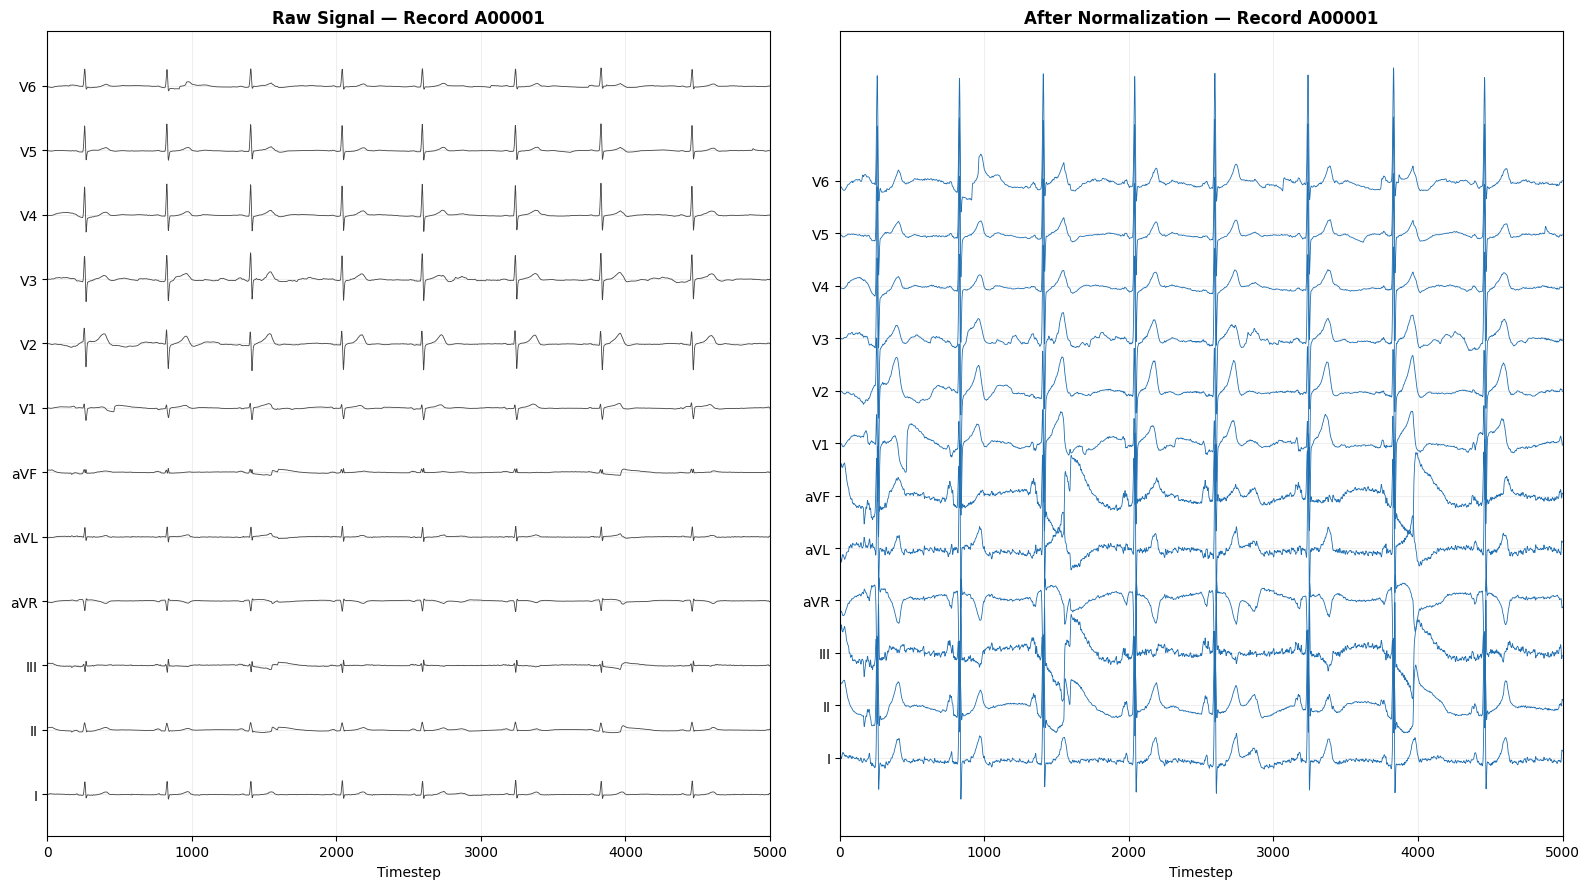

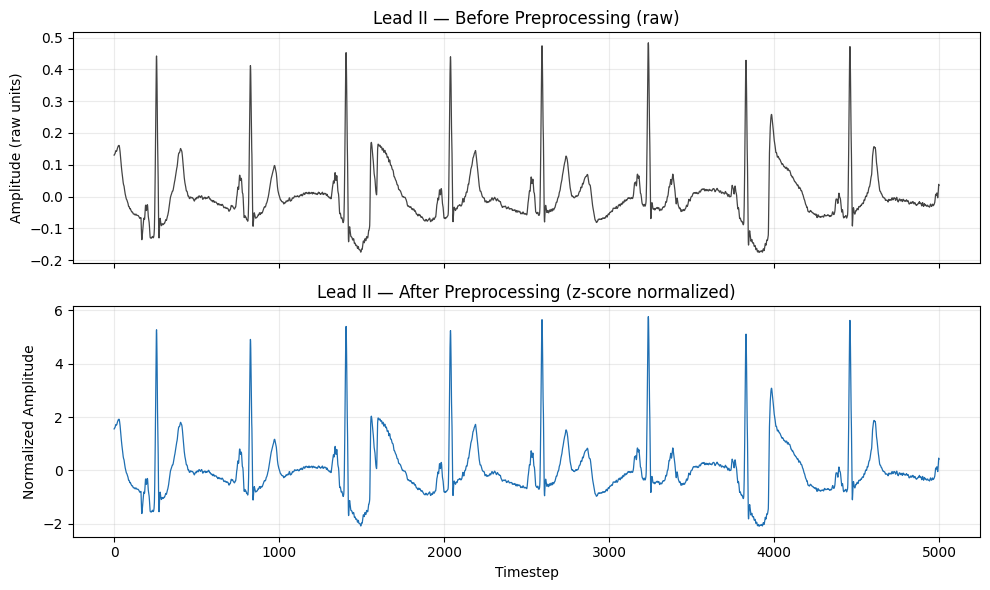

Record A00001 — Lead II:
  Raw    — mean: -0.0004, std: 0.0840
  Normed — mean: 0.0000, std: 1.0000  (should be ~0 and ~1)


In [ ]:
"""
Before/After Waveform Comparison — Raw vs. Preprocessed ECG Signal
=====================================================================
Loads a real record straight from the PTB-XL .h5 files and shows the
exact effect of the preprocessing pipeline (per-lead, per-record z-score
normalization), using the same formula as the main pipeline.

Drop this into your Colab notebook (after the PROJECT_DIR / path setup
cell) and run it — no changes needed if your folder structure matches
the rest of the project.
"""

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---------------------------------------------------------------
# Uses the same paths already defined earlier in your notebook.
# If running this standalone, uncomment and set these manually:
# PROJECT_DIR       = '/content/drive/MyDrive/ECG-Arrhythmia (1)'
# DATASET_DIR       = f'{PROJECT_DIR}/Dataset'
# PTBXL_RECORDS_DIR = f'{DATASET_DIR}/records'
# PTBXL_METADATA    = f'{DATASET_DIR}/metadata.csv'
# ---------------------------------------------------------------

LEAD_NAMES = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
T = 5000  # fixed length used throughout the project


def load_raw_record(ecg_id):
    """Loads one record's raw 12-lead signal straight from its .h5 file."""
    fpath = os.path.join(PTBXL_RECORDS_DIR, f'{ecg_id}.h5')
    with h5py.File(fpath, 'r') as f:
        ecg = f['ecg'][:]

    # same shape-fixing logic used during extraction
    if ecg.shape[1] >= T:
        ecg = ecg[:, :T]
    else:
        pad = np.zeros((12, T), dtype=np.float32)
        pad[:, :ecg.shape[1]] = ecg
        ecg = pad

    return ecg.astype(np.float32)


def normalize_record(ecg):
    """
    Exact same per-lead, per-record z-score normalization used in the
    main preprocessing pipeline — so this 'after' panel matches what
    the model actually receives as input.
    """
    normalized = np.zeros_like(ecg)
    for lead_idx in range(ecg.shape[0]):
        lead_data = ecg[lead_idx]
        mean = lead_data.mean()
        std = lead_data.std()
        if std < 1e-6:
            std = 1.0
        normalized[lead_idx] = (lead_data - mean) / std
    return normalized


def plot_before_after(ecg_id, lead_to_highlight='II', save_path=None):
    """
    Plots raw vs. normalized signal.
    - Top: all 12 leads, raw (stacked, offset for readability)
    - Bottom: all 12 leads, normalized (same layout)
    Also produces a second, larger single-lead close-up for the
    lead specified in `lead_to_highlight`, which is usually the
    clearest way to show the effect in a presentation slide.
    """
    raw = load_raw_record(ecg_id)
    norm = normalize_record(raw)

    # ---- Figure 1: all 12 leads, stacked, before vs after ----
    fig, axes = plt.subplots(1, 2, figsize=(16, 9))
    offset_step = 4  # vertical spacing between stacked leads

    for i, lead in enumerate(LEAD_NAMES):
        axes[0].plot(raw[i] + i * offset_step, linewidth=0.6, color='#444444')
        axes[1].plot(norm[i] + i * offset_step, linewidth=0.6, color='#1f6fb2')

    for ax, title in zip(axes, [f'Raw Signal — Record {ecg_id}', f'After Normalization — Record {ecg_id}']):
        ax.set_yticks([i * offset_step for i in range(12)])
        ax.set_yticklabels(LEAD_NAMES)
        ax.set_xlabel('Timestep')
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.set_xlim(0, T)
        ax.grid(alpha=0.2)

    plt.tight_layout()
    if save_path:
        plt.savefig(f'{save_path}_all_leads.png', dpi=150, bbox_inches='tight')
    plt.show()

    # ---- Figure 2: single-lead close-up, before vs after ----
    lead_idx = LEAD_NAMES.index(lead_to_highlight)
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    axes[0].plot(raw[lead_idx], color='#444444', linewidth=0.9)
    axes[0].set_title(f'Lead {lead_to_highlight} — Before Preprocessing (raw)', fontsize=12)
    axes[0].set_ylabel('Amplitude (raw units)')
    axes[0].grid(alpha=0.25)

    axes[1].plot(norm[lead_idx], color='#1f6fb2', linewidth=0.9)
    axes[1].set_title(f'Lead {lead_to_highlight} — After Preprocessing (z-score normalized)', fontsize=12)
    axes[1].set_ylabel('Normalized Amplitude')
    axes[1].set_xlabel('Timestep')
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    if save_path:
        plt.savefig(f'{save_path}_single_lead_{lead_to_highlight}.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f"Record {ecg_id} — Lead {lead_to_highlight}:")
    print(f"  Raw    — mean: {raw[lead_idx].mean():.4f}, std: {raw[lead_idx].std():.4f}")
    print(f"  Normed — mean: {norm[lead_idx].mean():.4f}, std: {norm[lead_idx].std():.4f}  (should be ~0 and ~1)")

    return raw, norm


# =================================================================
# USAGE
# =================================================================
# Option A — pick any specific record ID you know exists in your
# PTBXL_RECORDS_DIR (just the filename without ".h5"):
#
#   raw, norm = plot_before_after(ecg_id='00001_lr', lead_to_highlight='II',
#                                  save_path=f'{PROJECT_DIR}/waveform_images/before_after')
#
# Option B — grab the first available record automatically, useful if
# you don't already know a valid ID:

if __name__ == "__main__":
    df_meta = pd.read_csv(PTBXL_METADATA)
    example_id = df_meta['ECG_ID'].iloc[0]
    print(f"Using example record: {example_id}")

    raw, norm = plot_before_after(
        ecg_id=example_id,
        lead_to_highlight='II',
        save_path=f'{PROJECT_DIR}/waveform_images/before_after'
    )

In [ ]:
import h5py
import numpy as np
import pandas as pd
import os
from tqdm import tqdm

meta_index = {row['ECG_ID']: idx for idx, row in df_meta.iterrows()}
h5_files = sorted([f for f in os.listdir(PTBXL_RECORDS_DIR) if f.endswith('.h5')])
T = 5000
BATCH_SIZE = 1000

CHECKPOINT_DIR = f'{DATA_OUT_DIR}/checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Figure out which batches are already done (so reruns skip completed work)
existing_batches = set()
for fname in os.listdir(CHECKPOINT_DIR):
    if fname.startswith('batch_') and fname.endswith('_signals.npy'):
        batch_num = int(fname.split('_')[1])
        existing_batches.add(batch_num)

print(f"Already completed batches: {sorted(existing_batches)}")

n_batches = (len(h5_files) + BATCH_SIZE - 1) // BATCH_SIZE

for batch_idx in range(n_batches):
    if batch_idx in existing_batches:
        continue

    start = batch_idx * BATCH_SIZE
    end = min(start + BATCH_SIZE, len(h5_files))
    batch_files = h5_files[start:end]

    batch_signals, batch_labels, batch_ids = [], [], []

    for fname in tqdm(batch_files, desc=f"Batch {batch_idx+1}/{n_batches}"):
        ecg_id = fname.replace('.h5', '')
        if ecg_id not in meta_index:
            continue

        fpath = os.path.join(PTBXL_RECORDS_DIR, fname)
        try:
            with h5py.File(fpath, 'r') as f:
                ecg = f['ecg'][:]
        except Exception:
            continue

        if ecg.shape[1] >= T:
            ecg = ecg[:, :T]
        else:
            pad = np.zeros((12, T), dtype=np.float32)
            pad[:, :ecg.shape[1]] = ecg
            ecg = pad

        batch_signals.append(ecg.astype(np.float32))
        batch_labels.append(labels[meta_index[ecg_id]])
        batch_ids.append(ecg_id)

    np.save(f'{CHECKPOINT_DIR}/batch_{batch_idx}_signals.npy', np.stack(batch_signals))
    np.save(f'{CHECKPOINT_DIR}/batch_{batch_idx}_labels.npy', np.stack(batch_labels))
    np.save(f'{CHECKPOINT_DIR}/batch_{batch_idx}_ids.npy', np.array(batch_ids))

    print(f"Batch {batch_idx} saved ({len(batch_ids)} records)")

print("\nAll batches complete.")

Already completed batches: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]


Batch 1/26: 100%|██████████| 1000/1000 [08:42<00:00,  1.91it/s]


Batch 0 saved (1000 records)


Batch 2/26: 100%|██████████| 1000/1000 [00:05<00:00, 192.69it/s]


Batch 1 saved (1000 records)


Batch 3/26: 100%|██████████| 1000/1000 [00:05<00:00, 170.96it/s]


... (3 outputs left out)

Batch 5/26: 100%|██████████| 1000/1000 [00:06<00:00, 147.94it/s]


Batch 4 saved (1000 records)


Batch 6/26: 100%|██████████| 1000/1000 [00:05<00:00, 176.83it/s]


Batch 5 saved (1000 records)

All batches complete.


In [ ]:
import numpy as np
import os

CHECKPOINT_DIR = f'{DATA_OUT_DIR}/checkpoints'
n_batches = 26
T = 5000

# Get total record count first — cheap, only loads small id arrays
total_records = 0
for batch_idx in range(n_batches):
    ids = np.load(f'{CHECKPOINT_DIR}/batch_{batch_idx}_ids.npy')
    total_records += len(ids)

print(f"Total records: {total_records}")

# Create a DISK-BACKED array — lives in a file, not RAM
FINAL_SIGNALS_PATH = f'{DATA_OUT_DIR}/signals_all_memmap.npy'

signals_all = np.lib.format.open_memmap(
    FINAL_SIGNALS_PATH,
    mode='w+',
    dtype=np.float32,
    shape=(total_records, 12, T)
)

labels_all = np.zeros((total_records, 5), dtype=np.float32)
ecg_ids_used = []

write_pos = 0
for batch_idx in range(n_batches):
    s = np.load(f'{CHECKPOINT_DIR}/batch_{batch_idx}_signals.npy')
    l = np.load(f'{CHECKPOINT_DIR}/batch_{batch_idx}_labels.npy')
    i = np.load(f'{CHECKPOINT_DIR}/batch_{batch_idx}_ids.npy')

    n = s.shape[0]
    signals_all[write_pos:write_pos+n] = s
    labels_all[write_pos:write_pos+n]  = l
    ecg_ids_used.extend(i.tolist())

    write_pos += n
    del s, l, i
    print(f"Placed batch {batch_idx} ({n} records) — total so far: {write_pos}")

signals_all.flush()
ecg_ids_used = np.array(ecg_ids_used)

print(f"\nFinal signals (on disk): {signals_all.shape}")
print(f"Final labels (in RAM):   {labels_all.shape}")

unique_ids = len(set(ecg_ids_used))
print(f"Unique IDs: {unique_ids} / {len(ecg_ids_used)}")
print("✓ No duplicates" if unique_ids == len(ecg_ids_used) else "⚠️ Duplicates found")

Total records: 25770
Placed batch 0 (1000 records) — total so far: 1000
Placed batch 1 (1000 records) — total so far: 2000
Placed batch 2 (1000 records) — total so far: 3000
Placed batch 3 (1000 records) — total so far: 4000
Placed batch 4 (1000 records) — total so far: 5000
Placed batch 5 (1000 records) — total so far: 6000
Placed batch 6 (1000 records) — total so far: 7000
Placed batch 7 (1000 records) — total so far: 8000
Placed batch 8 (1000 records) — total so far: 9000
Placed batch 9 (1000 records) — total so far: 10000
Placed batch 10 (1000 records) — total so far: 11000
Placed batch 11 (1000 records) — total so far: 12000
Placed batch 12 (1000 records) — total so far: 13000
Placed batch 13 (1000 records) — total so far: 14000
Placed batch 14 (1000 records) — total so far: 15000
Placed batch 15 (1000 records) — total so far: 16000
Placed batch 16 (1000 records) — total so far: 17000
Placed batch 17 (1000 records) — total so far: 18000
Placed batch 18 (1000 records) — total so fa

In [ ]:
import numpy as np

n_records = signals_all.shape[0]
n_leads   = signals_all.shape[1]

for lead_idx in range(n_leads):
    lead_data = signals_all[:, lead_idx, :]  # loads just this lead — ~500MB, not 24GB

    mean = lead_data.mean(axis=1, keepdims=True)
    std  = lead_data.std(axis=1, keepdims=True)
    std[std < 1e-6] = 1.0

    signals_all[:, lead_idx, :] = (lead_data - mean) / std  # write back to disk

    del lead_data
    print(f"Normalized lead {lead_idx+1}/{n_leads}")

signals_all.flush()
print("\nNormalization complete.")

sample = signals_all[:100]
print(f"Sample mean: {sample.mean():.4f}  (should be ~0)")
print(f"Sample std:  {sample.std():.4f}   (should be ~1)")

signals_norm = signals_all  # alias, same memmap

Normalized lead 1/12
Normalized lead 2/12
Normalized lead 3/12
Normalized lead 4/12
Normalized lead 5/12
Normalized lead 6/12
Normalized lead 7/12
Normalized lead 8/12
Normalized lead 9/12
Normalized lead 10/12
Normalized lead 11/12
Normalized lead 12/12

Normalization complete.
Sample mean: 0.0000  (should be ~0)
Sample std:  1.0000   (should be ~1)


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

indices = np.arange(n_records)

stratify_key = np.argmax(labels_all, axis=1)
stratify_key[labels_all.sum(axis=1) == 0] = -1

idx_train, idx_test = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=stratify_key
)

idx_train = np.sort(idx_train)
idx_test  = np.sort(idx_test)

n_train = len(idx_train)
n_test  = len(idx_test)
print(f"Train: {n_train} records")
print(f"Test:  {n_test} records")

X_train = np.lib.format.open_memmap(f'{DATA_OUT_DIR}/X_train.npy', mode='w+', dtype=np.float32, shape=(n_train, 12, T))
X_test  = np.lib.format.open_memmap(f'{DATA_OUT_DIR}/X_test.npy',  mode='w+', dtype=np.float32, shape=(n_test, 12, T))

CHUNK = 500

for start in range(0, n_train, CHUNK):
    end = min(start + CHUNK, n_train)
    chunk_idx = idx_train[start:end]
    X_train[start:end] = signals_norm[chunk_idx]
    print(f"Train chunk {start}-{end} / {n_train}")

for start in range(0, n_test, CHUNK):
    end = min(start + CHUNK, n_test)
    chunk_idx = idx_test[start:end]
    X_test[start:end] = signals_norm[chunk_idx]
    print(f"Test chunk {start}-{end} / {n_test}")

X_train.flush()
X_test.flush()

y_train = labels_all[idx_train]
y_test  = labels_all[idx_test]

print(f"\nFinal X_train: {X_train.shape}")
print(f"Final y_train: {y_train.shape}")
print(f"Final X_test:  {X_test.shape}")
print(f"Final y_test:  {y_test.shape}")

Train: 20616 records
Test:  5154 records
Train chunk 0-500 / 20616
Train chunk 500-1000 / 20616
Train chunk 1000-1500 / 20616
Train chunk 1500-2000 / 20616
Train chunk 2000-2500 / 20616
Train chunk 2500-3000 / 20616
Train chunk 3000-3500 / 20616
Train chunk 3500-4000 / 20616
Train chunk 4000-4500 / 20616
Train chunk 4500-5000 / 20616
Train chunk 5000-5500 / 20616
Train chunk 5500-6000 / 20616
Train chunk 6000-6500 / 20616
Train chunk 6500-7000 / 20616
Train chunk 7000-7500 / 20616
Train chunk 7500-8000 / 20616
Train chunk 8000-8500 / 20616
Train chunk 8500-9000 / 20616
Train chunk 9000-9500 / 20616
Train chunk 9500-10000 / 20616
Train chunk 10000-10500 / 20616
Train chunk 10500-11000 / 20616
Train chunk 11000-11500 / 20616
Train chunk 11500-12000 / 20616
Train chunk 12000-12500 / 20616
Train chunk 12500-13000 / 20616
Train chunk 13000-13500 / 20616
Train chunk 13500-14000 / 20616
Train chunk 14000-14500 / 20616
Train chunk 14500-15000 / 20616
Train chunk 15000-15500 / 20616
Train chunk

In [ ]:
np.save(f'{DATA_OUT_DIR}/y_train.npy', y_train)
np.save(f'{DATA_OUT_DIR}/y_test.npy',  y_test)
np.save(f'{DATA_OUT_DIR}/ecg_ids.npy', np.array(ecg_ids_used))

print("Saved:")
print(f"  X_train.npy — {X_train.shape}  (already saved as memmap in Cell 6)")
print(f"  y_train.npy — {y_train.shape}")
print(f"  X_test.npy  — {X_test.shape}   (already saved as memmap in Cell 6)")
print(f"  y_test.npy  — {y_test.shape}")

Saved:
  X_train.npy — (20616, 12, 5000)  (already saved as memmap in Cell 6)
  y_train.npy — (20616, 5)
  X_test.npy  — (5154, 12, 5000)   (already saved as memmap in Cell 6)
  y_test.npy  — (5154, 5)


CELL 9 BELOW

In [ ]:
# Kaggle baseline dataset — loaded from preprocessed arrays
# (Raw CSVs: MIT-BIH Arrhythmia Database, INCART 2-lead Arrhythmia Database,
#  MIT-BIH Supraventricular Arrhythmia Database, Sudden Cardiac Death Holter Database)
# Labels follow AAMI EC57 standard: N=0, VEB=1, SVEB=2, F=3, Q=4
# Preprocessing: combined all 4 CSVs, dropped NaN labels, removed rows with
# NaN/Inf features, encoded labels as integers. Final shape: (712822, 32).

X_kaggle = np.load(f'{DATA_OUT_DIR}/X_kaggle.npy')
y_kaggle = np.load(f'{DATA_OUT_DIR}/y_kaggle.npy')

print(f"X_kaggle: {X_kaggle.shape}  dtype: {X_kaggle.dtype}")
print(f"y_kaggle: {y_kaggle.shape}  dtype: {y_kaggle.dtype}")
print(f"\nClass distribution:")

AAMI_LABELS = {0: 'N (Normal)', 1: 'VEB (Ventricular Ectopic)',
               2: 'SVEB (Supraventricular Ectopic)', 3: 'F (Fusion)', 4: 'Q (Unknown)'}
for i, name in AAMI_LABELS.items():
    count = (y_kaggle == i).sum()
    print(f"  {name}: {count:,} ({count/len(y_kaggle)*100:.1f}%)")

print(f"\nTotal heartbeats: {len(y_kaggle):,}")
print(f"Features per beat: {X_kaggle.shape[1]} (RR intervals, peak amplitudes, "
      f"QRS/PQ/QT/ST intervals, QRS morphology)")

X_kaggle: (712822, 32)  dtype: float32
y_kaggle: (712822,)  dtype: int64

Class distribution:
  N (Normal): 644,711 (90.4%)
  VEB (Ventricular Ectopic): 48,212 (6.8%)
  SVEB (Supraventricular Ectopic): 18,501 (2.6%)
  F (Fusion): 1,255 (0.2%)
  Q (Unknown): 143 (0.0%)

Total heartbeats: 712,822
Features per beat: 32 (RR intervals, peak amplitudes, QRS/PQ/QT/ST intervals, QRS morphology)


In [ ]:
import glob
import pandas as pd
import numpy as np

kaggle_files = glob.glob(f'{KAGGLE_DIR}/*.csv')
print("Kaggle CSVs found:", [os.path.basename(f) for f in kaggle_files])

dfs = []
for fpath in kaggle_files:
    if 'gsheet' in fpath.lower():
        continue
    df = pd.read_csv(fpath, header=0, low_memory=False)
    df['source_db'] = os.path.basename(fpath).replace('.csv', '')
    print(f"{os.path.basename(fpath)} — shape: {df.shape}")
    dfs.append(df)

df_kaggle = pd.concat(dfs, ignore_index=True)
print(f"\nCombined shape: {df_kaggle.shape}")
print(f"\nLabel distribution:\n{df_kaggle['type'].value_counts()}")

Kaggle CSVs found: ['INCART 2-lead Arrhythmia Database.csv', 'MIT-BIH Arrhythmia Database.csv', 'MIT-BIH Supraventricular Arrhythmia Database.csv', 'Sudden Cardiac Death Holter Database.csv']
INCART 2-lead Arrhythmia Database.csv — shape: (175729, 35)
MIT-BIH Arrhythmia Database.csv — shape: (100689, 35)
MIT-BIH Supraventricular Arrhythmia Database.csv — shape: (184428, 35)
Sudden Cardiac Death Holter Database.csv — shape: (502808, 35)

Combined shape: (963654, 35)

Label distribution:
type
N       809352
VEB      51669
SVEB     18540
Q         6620
F         1256
Name: count, dtype: int64


In [ ]:
import numpy as np

# Drop any rows with missing/invalid type labels
print(f"Before dropping NaNs: {df_kaggle.shape}")
df_kaggle = df_kaggle.dropna(subset=['type'])
print(f"After dropping NaNs:  {df_kaggle.shape}")

LABEL_MAP = {'N': 0, 'VEB': 1, 'SVEB': 2, 'F': 3, 'Q': 4}
df_kaggle = df_kaggle[df_kaggle['type'].isin(LABEL_MAP.keys())]
print(f"After filtering unknown labels: {df_kaggle.shape}")

feature_cols = [c for c in df_kaggle.columns if c not in ['record', 'type', 'source_db']]
print(f"\nNumber of feature columns: {len(feature_cols)}")  # should be 32

X_kaggle = df_kaggle[feature_cols].values.astype(np.float32)
y_kaggle = df_kaggle['type'].map(LABEL_MAP).values.astype(np.int64)

print(f"\nX_kaggle: {X_kaggle.shape}")
print(f"y_kaggle: {y_kaggle.shape}, classes: {np.unique(y_kaggle)}")
print(f"\nClass distribution:")
for label_name, label_idx in LABEL_MAP.items():
    count = (y_kaggle == label_idx).sum()
    print(f"  {label_idx} ({label_name}): {count}")

n_bad = ~np.isfinite(X_kaggle).all(axis=1)
print(f"\nRows with NaN/Inf in features: {n_bad.sum()}")
if n_bad.sum() > 0:
    X_kaggle = X_kaggle[~n_bad]
    y_kaggle = y_kaggle[~n_bad]
    print(f"Cleaned shape: X={X_kaggle.shape}, y={y_kaggle.shape}")

np.save(f'{DATA_OUT_DIR}/X_kaggle.npy', X_kaggle)
np.save(f'{DATA_OUT_DIR}/y_kaggle.npy', y_kaggle)
print("\nKaggle data saved.")

Before dropping NaNs: (963654, 35)
After dropping NaNs:  (887437, 35)
After filtering unknown labels: (887437, 35)

Number of feature columns: 32

X_kaggle: (887437, 32)
y_kaggle: (887437,), classes: [0 1 2 3 4]

Class distribution:
  0 (N): 809352
  1 (VEB): 51669
  2 (SVEB): 18540
  3 (F): 1256
  4 (Q): 6620

Rows with NaN/Inf in features: 174615
Cleaned shape: X=(712822, 32), y=(712822,)

Kaggle data saved.


In [ ]:
print("=" * 50)
print("DATA CONTRACT — ECG Project")
print("=" * 50)
print(f"Location: Google Drive → ECG-Arrhythmia/processed_data/")
print()
print("PTB-XL FILES:")
print(f"  X_train.npy — shape: {X_train.shape}  dtype: float32")
print(f"  y_train.npy — shape: {y_train.shape}  dtype: float32 (multi-hot)")
print(f"  X_test.npy  — shape: {X_test.shape}   dtype: float32")
print(f"  y_test.npy  — shape: {y_test.shape}   dtype: float32")
print()
print("LABEL INDEX MAPPING (PTB-XL):")
for i, sc in enumerate(SUPERCLASSES):
    print(f"  {i} = {sc}")
print()
print("LEAD INDEX MAPPING (axis 1):")
leads = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']
for i, l in enumerate(leads):
    print(f"  {i} = {l}")
print()
print("SIGNAL FORMAT (PTB-XL):")
print("  Shape: (samples, 12 leads, 5000 timesteps)")
print("  Sampling rate: 500 Hz → 10 seconds per record")
print("  Normalization: Z-score per lead per sample")
print()
print("KAGGLE BASELINE FILES:")
print(f"  X_kaggle.npy — shape: {X_kaggle.shape}  dtype: float32 (32 hand-crafted features per beat)")
print(f"  y_kaggle.npy — shape: {y_kaggle.shape}  dtype: int64")
print()
print("LABEL INDEX MAPPING (Kaggle, AAMI EC57 standard):")
print("  0 = N    (Normal)")
print("  1 = VEB  (Ventricular Ectopic Beat)")
print("  2 = SVEB (Supraventricular Ectopic Beat)")
print("  3 = F    (Fusion Beat)")
print("  4 = Q    (Unknown/Paced Beat)")
print()
print("NOTE: Kaggle dataset is feature-based (pre-extracted RR intervals, peak")
print("amplitudes, QRS/PQ/QT/ST intervals, morphology), NOT raw waveform signal —")
print("differs structurally from PTB-XL. Treat as separate baseline, not mergeable")
print("with PTB-XL signals directly.")
print()
print("CLASS IMBALANCE WARNING (Kaggle): ~84% Normal, F class <0.2% of data —")
print("use F1/precision/recall per class, not accuracy alone.")
print("=" * 50)

DATA CONTRACT — ECG Project
Location: Google Drive → ECG-Arrhythmia/processed_data/

PTB-XL FILES:
  X_train.npy — shape: (20616, 12, 5000)  dtype: float32
  y_train.npy — shape: (20616, 5)  dtype: float32 (multi-hot)
  X_test.npy  — shape: (5154, 12, 5000)   dtype: float32
  y_test.npy  — shape: (5154, 5)   dtype: float32

LABEL INDEX MAPPING (PTB-XL):
  0 = NORM
  1 = MI
  2 = STTC
  3 = CD
  4 = HYP

LEAD INDEX MAPPING (axis 1):
  0 = I
  1 = II
  2 = III
  3 = aVR
  4 = aVL
  5 = aVF
  6 = V1
  7 = V2
  8 = V3
  9 = V4
  10 = V5
  11 = V6

SIGNAL FORMAT (PTB-XL):
  Shape: (samples, 12 leads, 5000 timesteps)
  Sampling rate: 500 Hz → 10 seconds per record
  Normalization: Z-score per lead per sample

KAGGLE BASELINE FILES:
  X_kaggle.npy — shape: (712822, 32)  dtype: float32 (32 hand-crafted features per beat)
  y_kaggle.npy — shape: (712822,)  dtype: int64

LABEL INDEX MAPPING (Kaggle, AAMI EC57 standard):
  0 = N    (Normal)
  1 = VEB  (Ventricular Ectopic Beat)
  2 = SVEB (Suprav

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score, classification_report
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [ ]:
# Load Kaggle data
X_kaggle = np.load(f'{DATA_OUT_DIR}/X_kaggle.npy')
y_kaggle = np.load(f'{DATA_OUT_DIR}/y_kaggle.npy')

print(f"X_kaggle: {X_kaggle.shape}, y_kaggle: {y_kaggle.shape}")

# Train/test split for baseline
from sklearn.model_selection import train_test_split
Xk_train, Xk_test, yk_train, yk_test = train_test_split(
    X_kaggle, y_kaggle, test_size=0.2, random_state=42, stratify=y_kaggle
)

# Normalize features (z-score per column, fit on train only)
feat_mean = Xk_train.mean(axis=0, keepdims=True)
feat_std  = Xk_train.std(axis=0, keepdims=True)
feat_std[feat_std < 1e-6] = 1.0

Xk_train = (Xk_train - feat_mean) / feat_std
Xk_test  = (Xk_test  - feat_mean) / feat_std

print(f"Train: {Xk_train.shape}, Test: {Xk_test.shape}")

X_kaggle: (712822, 32), y_kaggle: (712822,)
Train: (570257, 32), Test: (142565, 32)


In [ ]:
class KaggleDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_ds = KaggleDataset(Xk_train, yk_train)
test_ds  = KaggleDataset(Xk_test, yk_test)

train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)
test_loader  = DataLoader(test_ds, batch_size=256, shuffle=False)

**BASELINE MODEL**

In [ ]:
class BaselineNet(nn.Module):
    def __init__(self, input_dim=32, num_classes=5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.net(x)

baseline_model = BaselineNet().to(device)
print(baseline_model)

BaselineNet(
  (net): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=5, bias=True)
  )
)


In [ ]:
# Handle class imbalance (remember: N is 84%, F is <0.2%)
from collections import Counter
class_counts = Counter(yk_train.tolist())
total = len(yk_train)
class_weights = torch.tensor(
    [total / (5 * class_counts[i]) for i in range(5)],
    dtype=torch.float32
).to(device)
print(f"Class weights: {class_weights}")

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)

Class weights: tensor([2.2113e-01, 2.9570e+00, 7.7057e+00, 1.1360e+02, 1.0005e+03],
       device='cuda:0')


In [ ]:
# Training loop
EPOCHS = 15

for epoch in range(EPOCHS):
    baseline_model.train()
    total_loss = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = baseline_model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # Quick eval each epoch
    baseline_model.eval()
    all_preds, all_true = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            out = baseline_model(xb)
            preds = out.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_true.extend(yb.numpy())

    f1 = f1_score(all_true, all_preds, average='macro')
    print(f"Epoch {epoch+1}/{EPOCHS} — Loss: {total_loss/len(train_loader):.4f} — Macro F1: {f1:.4f}")

Epoch 1/15 — Loss: 0.7916 — Macro F1: 0.4539
Epoch 2/15 — Loss: 0.6120 — Macro F1: 0.4560
Epoch 3/15 — Loss: 0.5507 — Macro F1: 0.4730
Epoch 4/15 — Loss: 0.5201 — Macro F1: 0.4522
Epoch 5/15 — Loss: 0.4931 — Macro F1: 0.4670
Epoch 6/15 — Loss: 0.4777 — Macro F1: 0.4715
Epoch 7/15 — Loss: 0.4620 — Macro F1: 0.4787
Epoch 8/15 — Loss: 0.4645 — Macro F1: 0.4747
Epoch 9/15 — Loss: 0.4500 — Macro F1: 0.4963
Epoch 10/15 — Loss: 0.4391 — Macro F1: 0.4687
Epoch 11/15 — Loss: 0.4365 — Macro F1: 0.4866
Epoch 12/15 — Loss: 0.4311 — Macro F1: 0.4825
Epoch 13/15 — Loss: 0.4237 — Macro F1: 0.5022
Epoch 14/15 — Loss: 0.4109 — Macro F1: 0.5022
Epoch 15/15 — Loss: 0.4087 — Macro F1: 0.5052


In [ ]:
# Softer class weighting — square root dampens the extreme weights
class_weights_soft = torch.tensor(
    [(total / (5 * class_counts[i])) ** 0.5 for i in range(5)],
    dtype=torch.float32
).to(device)
print(f"Original weights: {class_weights}")
print(f"Softened weights: {class_weights_soft}")

criterion = nn.CrossEntropyLoss(weight=class_weights_soft)
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)

# Re-initialize model fresh and retrain with softened weights
baseline_model = BaselineNet().to(device)
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)

for epoch in range(EPOCHS):
    baseline_model.train()
    total_loss = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = baseline_model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    baseline_model.eval()
    all_preds, all_true = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            out = baseline_model(xb)
            preds = out.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_true.extend(yb.numpy())

    f1 = f1_score(all_true, all_preds, average='macro')
    print(f"Epoch {epoch+1}/{EPOCHS} — Loss: {total_loss/len(train_loader):.4f} — Macro F1: {f1:.4f}")

print(classification_report(all_true, all_preds, target_names=['N', 'VEB', 'SVEB', 'F', 'Q']))
torch.save(baseline_model.state_dict(), f'{PROJECT_DIR}/baseline_model.pt')

Original weights: tensor([2.2113e-01, 2.9570e+00, 7.7057e+00, 1.1360e+02, 1.0005e+03],
       device='cuda:0')
Softened weights: tensor([ 0.4702,  1.7196,  2.7759, 10.6582, 31.6299], device='cuda:0')
Epoch 1/15 — Loss: 0.4500 — Macro F1: 0.6169
Epoch 2/15 — Loss: 0.3047 — Macro F1: 0.6472
Epoch 3/15 — Loss: 0.2766 — Macro F1: 0.6474
Epoch 4/15 — Loss: 0.2580 — Macro F1: 0.6753
Epoch 5/15 — Loss: 0.2464 — Macro F1: 0.6732
Epoch 6/15 — Loss: 0.2435 — Macro F1: 0.7024
Epoch 7/15 — Loss: 0.2342 — Macro F1: 0.7080
Epoch 8/15 — Loss: 0.2289 — Macro F1: 0.6879
Epoch 9/15 — Loss: 0.2273 — Macro F1: 0.6624
Epoch 10/15 — Loss: 0.2240 — Macro F1: 0.7063
Epoch 11/15 — Loss: 0.2216 — Macro F1: 0.7011
Epoch 12/15 — Loss: 0.2183 — Macro F1: 0.6834
Epoch 13/15 — Loss: 0.2158 — Macro F1: 0.6976
Epoch 14/15 — Loss: 0.2114 — Macro F1: 0.6850
Epoch 15/15 — Loss: 0.2105 — Macro F1: 0.6994
              precision    recall  f1-score   support

           N       1.00      0.98      0.99    128943
         V

**PRIMARY MODEL**

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score, classification_report
import matplotlib.pyplot as plt

class PTBXLDataset(Dataset):
    """
    Wraps the memmap arrays so PyTorch reads one record at a time from disk
    rather than loading everything into RAM.
    """
    def __init__(self, X_memmap, y_array):
        self.X = X_memmap
        self.y = y_array

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = np.array(self.X[idx], dtype=np.float32)
        y = self.y[idx].astype(np.float32)
        return torch.from_numpy(x), torch.from_numpy(y)

train_dataset = PTBXLDataset(X_train, y_train)
test_dataset  = PTBXLDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}, Test batches: {len(test_loader)}")

xb, yb = next(iter(train_loader))
print(f"Batch X shape: {xb.shape}")
print(f"Batch y shape: {yb.shape}")

Train batches: 645, Test batches: 162
Batch X shape: torch.Size([32, 12, 5000])
Batch y shape: torch.Size([32, 5])


In [ ]:
class LeadCNN(nn.Module):
    """
    Runs a small 1D CNN independently across each of the 12 leads.
    Shares weights across leads — same pattern-spotter logic applied to all 12.
    """
    def __init__(self, in_channels=1, out_channels=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels, 16, kernel_size=7, padding=3),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm1d(out_channels),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.conv(x)  # (batch, out_channels, time/4)


class ChannelAttention(nn.Module):
    """
    Learns how much to weight each of the 12 leads for this particular sample.
    """
    def __init__(self, n_leads=12, feature_dim=32):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(feature_dim, feature_dim // 2),
            nn.ReLU(),
            nn.Linear(feature_dim // 2, 1)
        )

    def forward(self, lead_features):
        scores = self.attn(lead_features)
        weights = F.softmax(scores, dim=1)
        weighted = lead_features * weights
        return weighted, weights.squeeze(-1)


class ECG_CNN_BiLSTM(nn.Module):
    """
    Full pipeline: per-lead CNN -> channel attention -> BiLSTM -> classification head.
    """
    def __init__(self, n_leads=12, cnn_out=32, lstm_hidden=64, num_classes=5):
        super().__init__()
        self.n_leads = n_leads
        self.lead_cnn = LeadCNN(in_channels=1, out_channels=cnn_out)
        self.attention = ChannelAttention(n_leads=n_leads, feature_dim=cnn_out)

        self.bilstm = nn.LSTM(
            input_size=cnn_out,
            hidden_size=lstm_hidden,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x, return_attention=False):
        batch_size = x.shape[0]
        x = x.view(batch_size * self.n_leads, 1, -1)
        cnn_out = self.lead_cnn(x)
        cnn_out = cnn_out.mean(dim=2)
        cnn_out = cnn_out.view(batch_size, self.n_leads, -1)

        attended, attn_weights = self.attention(cnn_out)
        lstm_out, _ = self.bilstm(attended)
        final_repr = lstm_out[:, -1, :]
        logits = self.classifier(final_repr)

        if return_attention:
            return logits, attn_weights
        return logits

model = ECG_CNN_BiLSTM(n_leads=12, cnn_out=32, lstm_hidden=64, num_classes=5).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {n_params:,}")
print(model)

Total parameters: 65,286
ECG_CNN_BiLSTM(
  (lead_cnn): LeadCNN(
    (conv): Sequential(
      (0): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
      (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): ReLU()
      (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (8): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
      (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (10): ReLU()
    )
  )
  (attention): ChannelAttention(
    (attn): Sequential(
      (0): Linear(in_features=32, out_features=16, bias=True)
      (1): ReLU()
      (2): Linear(in_features=16, out_features=1, bia

In [ ]:
class LeadCNN(nn.Module):
    """4 conv blocks now, up from 3 — deeper local feature extraction per lead."""
    def __init__(self, in_channels=1, out_channels=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels, 16, kernel_size=7, padding=3),
            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),

            nn.Conv1d(32, 32, kernel_size=3, padding=1),   # new 4th block
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),

            nn.Conv1d(32, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm1d(out_channels), nn.ReLU(),
        )

    def forward(self, x):
        return self.conv(x)


class ChannelAttention(nn.Module):
    """Original, proven design — independent per-lead scoring, no self-attention mixing."""
    def __init__(self, n_leads=12, feature_dim=32):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(feature_dim, feature_dim // 2),
            nn.ReLU(),
            nn.Linear(feature_dim // 2, 1)
        )

    def forward(self, lead_features):
        scores = self.attn(lead_features)
        weights = F.softmax(scores, dim=1)
        weighted = lead_features * weights
        return weighted, weights.squeeze(-1)


class ECG_CNN_MHA_BiLSTM(nn.Module):
    """Final model: deeper CNN + proven ChannelAttention + stacked 2-layer BiLSTM."""
    def __init__(self, n_leads=12, cnn_out=32, lstm_hidden=64, num_classes=5,
                 lstm_layers=2, lstm_dropout=0.3, head_dropout=0.3):
        super().__init__()
        self.n_leads = n_leads
        self.lead_cnn = LeadCNN(in_channels=1, out_channels=cnn_out)
        self.attention = ChannelAttention(n_leads=n_leads, feature_dim=cnn_out)

        self.bilstm = nn.LSTM(
            input_size=cnn_out, hidden_size=lstm_hidden, num_layers=lstm_layers,
            batch_first=True, bidirectional=True,
            dropout=lstm_dropout if lstm_layers > 1 else 0.0
        )

        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden * 2, 64), nn.ReLU(), nn.Dropout(head_dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x, return_attention=False):
        batch_size = x.shape[0]
        x = x.view(batch_size * self.n_leads, 1, -1)
        cnn_out = self.lead_cnn(x)
        cnn_out = cnn_out.mean(dim=2)
        cnn_out = cnn_out.view(batch_size, self.n_leads, -1)

        attended, attn_weights = self.attention(cnn_out)
        lstm_out, _ = self.bilstm(attended)
        final_repr = lstm_out[:, -1, :]
        logits = self.classifier(final_repr)

        if return_attention:
            return logits, attn_weights
        return logits


model_upgraded = ECG_CNN_MHA_BiLSTM(
    n_leads=12, cnn_out=32, lstm_hidden=64, num_classes=5,
    lstm_layers=2, lstm_dropout=0.3, head_dropout=0.5
).to(device)

n_params_upgraded = sum(p.numel() for p in model_upgraded.parameters())
print(f"Upgraded model — Total parameters: {n_params_upgraded:,}")

Upgraded model — Total parameters: 167,782


In [ ]:
import torch

checkpoint_path = f'{PROJECT_DIR}/best_cnn_final_v2.pt'
checkpoint = torch.load(checkpoint_path, map_location=device)

# Load weights into the upgraded architecture
if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
    model_upgraded.load_state_dict(checkpoint['model_state_dict'])
elif isinstance(checkpoint, dict) and 'state_dict' in checkpoint:
    model_upgraded.load_state_dict(checkpoint['state_dict'])
else:
    model_upgraded.load_state_dict(checkpoint)

model_upgraded.eval()
model = model_upgraded  # bind to 'model' so all downstream cells work

print(f"Model loaded from: {checkpoint_path}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Ready.")

Model loaded from: /content/drive/MyDrive/ECG-Arrhythmia (1)/best_cnn_final_v2.pt
Parameters: 167,782
Ready.


In [ ]:
# Keep the original trained model accessible under its own name for later comparison
model_original = model  # ECG_CNN_BiLSTM (single-head attention, 1-layer BiLSTM) — already trained, checkpoint saved

# Rebind `model` to the upgraded architecture so all downstream cells (loss, training loop,
# evaluation, Grad-CAM) use it without needing individual edits
model = model_upgraded  # ECG_CNN_MHA_BiLSTM (multi-head attention, 2-layer BiLSTM) — untrained

print("Active model is now: ECG_CNN_MHA_BiLSTM (multi-head attention + stacked BiLSTM)")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Active model is now: ECG_CNN_MHA_BiLSTM (multi-head attention + stacked BiLSTM)
Parameters: 167,782


In [ ]:
# Multi-label = BCEWithLogitsLoss, not CrossEntropyLoss
# (a patient can have NORM=0, MI=1, CD=1 simultaneously — these aren't mutually exclusive)

# Compute per-class positive weights to handle imbalance (remember: MI has only 260 samples)
pos_counts = y_train.sum(axis=0)
neg_counts = len(y_train) - pos_counts
pos_weight = torch.tensor(neg_counts / (pos_counts + 1e-6), dtype=torch.float32).to(device)

print("Class balance in training set:")
for i, sc in enumerate(SUPERCLASSES):
    print(f"  {sc}: {int(pos_counts[i])} positive / {len(y_train)} total — pos_weight={pos_weight[i]:.2f}")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

Class balance in training set:
  NORM: 11124 positive / 20616 total — pos_weight=0.85
  MI: 208 positive / 20616 total — pos_weight=98.12
  STTC: 4101 positive / 20616 total — pos_weight=4.03
  CD: 1993 positive / 20616 total — pos_weight=9.34
  HYP: 669 positive / 20616 total — pos_weight=29.82


In [ ]:
def evaluate(model, loader, criterion, device, threshold=0.5):
    model.eval()
    total_loss = 0
    all_logits, all_true = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item()
            all_logits.append(logits.cpu())
            all_true.append(yb.cpu())

    all_logits = torch.cat(all_logits).numpy()
    all_true   = torch.cat(all_true).numpy()
    all_probs  = 1 / (1 + np.exp(-all_logits))  # sigmoid
    all_preds  = (all_probs >= threshold).astype(int)

    macro_f1 = f1_score(all_true, all_preds, average='macro', zero_division=0)

    aurocs = []
    for i in range(all_true.shape[1]):
        if all_true[:, i].sum() > 0 and all_true[:, i].sum() < len(all_true):
            aurocs.append(roc_auc_score(all_true[:, i], all_probs[:, i]))
        else:
            aurocs.append(float('nan'))

    avg_loss = total_loss / len(loader)
    return avg_loss, macro_f1, aurocs, all_true, all_preds, all_probs


EPOCHS = 60
best_f1 = 0
best_val_loss = float('inf')
patience = 10
epochs_no_improve = 0

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    train_loss = total_loss / len(train_loader)
    val_loss, val_f1, val_aurocs, _, _, _ = evaluate(model, test_loader, criterion, device)
    scheduler.step(val_loss)

    auroc_str = " ".join([f"{SUPERCLASSES[i]}={val_aurocs[i]:.3f}" for i in range(5)])
    print(f"Epoch {epoch+1}/{EPOCHS} — Train Loss: {train_loss:.4f} — Val Loss: {val_loss:.4f} — Val Macro F1: {val_f1:.4f}")
    print(f"  AUROC: {auroc_str}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(), f'{PROJECT_DIR}/best_cnn_final_v2.pt')
        print(f"  ✓ New best model saved (F1={best_f1:.4f})")

    # Early stopping — watches VAL LOSS, not F1, since loss is what actually reveals overfitting
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch+1} — val loss hasn't improved in {patience} epochs.")
            break

print(f"\nTraining complete. Best macro F1: {best_f1:.4f}")

Epoch 1/60 — Train Loss: 0.6097 — Val Loss: 0.6917 — Val Macro F1: 0.4306
  AUROC: NORM=0.816 MI=0.977 STTC=0.931 CD=0.872 HYP=0.822
  ✓ New best model saved (F1=0.4306)
Epoch 2/60 — Train Loss: 0.6126 — Val Loss: 0.5959 — Val Macro F1: 0.4722
  AUROC: NORM=0.822 MI=0.979 STTC=0.940 CD=0.895 HYP=0.875
  ✓ New best model saved (F1=0.4722)
Epoch 3/60 — Train Loss: 0.5986 — Val Loss: 0.6077 — Val Macro F1: 0.5046
  AUROC: NORM=0.830 MI=0.980 STTC=0.940 CD=0.902 HYP=0.884
  ✓ New best model saved (F1=0.5046)
Epoch 4/60 — Train Loss: 0.5862 — Val Loss: 0.6236 — Val Macro F1: 0.4187
  AUROC: NORM=0.824 MI=0.982 STTC=0.933 CD=0.900 HYP=0.880
Epoch 5/60 — Train Loss: 0.5741 — Val Loss: 0.6469 — Val Macro F1: 0.5101
  AUROC: NORM=0.835 MI=0.967 STTC=0.942 CD=0.914 HYP=0.890
  ✓ New best model saved (F1=0.5101)
Epoch 6/60 — Train Loss: 0.6576 — Val Loss: 0.5629 — Val Macro F1: 0.4893
  AUROC: NORM=0.824 MI=0.985 STTC=0.934 CD=0.914 HYP=0.878
Epoch 7/60 — Train Loss: 0.5623 — Val Loss: 0.5771 — V

In [ ]:
attn_importance_matrix = np.zeros((5, 12))
for class_idx in range(5):
    importance = compute_attention_lead_importance(model, X_test, y_test, class_idx)
    attn_importance_matrix[class_idx] = importance
    top3 = np.argsort(importance)[::-1][:3]
    top3_str = ", ".join([f"{LEAD_NAMES[i]} ({importance[i]:.3f})" for i in top3])
    print(f"  {SUPERCLASSES[class_idx]}: top leads = {top3_str}")

NameError: name 'compute_attention_lead_importance' is not defined

In [ ]:
model.eval()
_, _, _, y_true_final, _, y_probs_final = evaluate(model, test_loader, criterion, device)

best_thresholds = []
for i in range(5):
    best_f1_class, best_t = 0, 0.5
    for t in np.arange(0.05, 0.95, 0.05):
        preds_i = (y_probs_final[:, i] >= t).astype(int)
        f1_i = f1_score(y_true_final[:, i], preds_i, zero_division=0)
        if f1_i > best_f1_class:
            best_f1_class, best_t = f1_i, t
    best_thresholds.append(best_t)
    print(f"{SUPERCLASSES[i]}: best threshold={best_t:.2f}, F1={best_f1_class:.4f}")

best_thresholds = np.array(best_thresholds)
final_preds = (y_probs_final >= best_thresholds).astype(int)
print(classification_report(y_true_final, final_preds, target_names=SUPERCLASSES, zero_division=0))
print(f"Final Macro F1: {f1_score(y_true_final, final_preds, average='macro', zero_division=0):.4f}")

NORM: best threshold=0.35, F1=0.8146
MI: best threshold=0.90, F1=0.4756
STTC: best threshold=0.75, F1=0.7705
CD: best threshold=0.85, F1=0.6951
HYP: best threshold=0.90, F1=0.3469
              precision    recall  f1-score   support

        NORM       0.73      0.93      0.81      2781
          MI       0.35      0.75      0.48        52
        STTC       0.78      0.77      0.77      1024
          CD       0.79      0.62      0.70       486
         HYP       0.32      0.38      0.35       170

   micro avg       0.72      0.84      0.77      4513
   macro avg       0.59      0.69      0.62      4513
weighted avg       0.72      0.84      0.77      4513
 samples avg       0.70      0.71      0.70      4513

Final Macro F1: 0.6205


In [ ]:
print(f"Checkpoint file: {PROJECT_DIR}/best_cnn_final_v2.pt")

Checkpoint file: /content/drive/MyDrive/ECG-Arrhythmia (1)/best_cnn_final_v2.pt


In [ ]:
def compute_occlusion_importance(model, X_data, y_data, class_idx, max_samples=200):
    """
    For each positive sample, measure how much the predicted probability
    for class_idx DROPS when each lead is individually zeroed out.
    Bigger drop = that lead mattered more for this prediction.
    """
    positive_indices = np.where(y_data[:, class_idx] == 1)[0]
    if len(positive_indices) > max_samples:
        positive_indices = np.random.choice(positive_indices, max_samples, replace=False)

    importance_sum = np.zeros(12)
    model.eval()

    with torch.no_grad():
        for idx in positive_indices:
            x = torch.tensor(np.array(X_data[idx]), dtype=torch.float32).unsqueeze(0).to(device)
            baseline_prob = torch.sigmoid(model(x))[0, class_idx].item()

            for lead_idx in range(12):
                x_occluded = x.clone()
                x_occluded[0, lead_idx, :] = 0  # zero out this lead entirely
                occluded_prob = torch.sigmoid(model(x_occluded))[0, class_idx].item()
                importance_sum[lead_idx] += (baseline_prob - occluded_prob)  # drop in confidence

    importance_avg = importance_sum / len(positive_indices)
    return importance_avg

occlusion_importance_matrix = np.zeros((5, 12))

print("Computing occlusion-based lead importance per class (this may take a minute)...")
for class_idx in range(5):
    importance = compute_occlusion_importance(model, X_test, y_test, class_idx)
    occlusion_importance_matrix[class_idx] = importance
    top3 = np.argsort(importance)[::-1][:3]
    top3_str = ", ".join([f"{LEAD_NAMES[i]} ({importance[i]:.4f})" for i in top3])
    print(f"  {SUPERCLASSES[class_idx]}: top leads = {top3_str}")

np.save(f'{PROJECT_DIR}/occlusion_lead_importance_matrix.npy', occlusion_importance_matrix)
print("\nOcclusion-based lead importance saved.")

Computing occlusion-based lead importance per class (this may take a minute)...
  NORM: top leads = II (0.2081), I (0.1985), V6 (0.1618)
  MI: top leads = aVF (0.2132), V2 (0.1312), V1 (0.1263)
  STTC: top leads = aVR (0.0616), aVL (0.0355), V1 (0.0216)
  CD: top leads = V1 (0.1379), aVF (0.0603), V2 (0.0578)
  HYP: top leads = aVR (0.1725), aVL (0.0659), aVF (0.0542)

Occlusion-based lead importance saved.


CELL 30 BELOW

In [ ]:
for i, layer in enumerate(model.lead_cnn.conv):
    print(i, layer)

0 Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
1 BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
2 ReLU()
3 MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
4 Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
5 BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
6 ReLU()
7 MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
8 Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
9 BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
10 ReLU()
11 MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
12 Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
13 BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
14 ReLU()


In [ ]:
target_layer = model.lead_cnn.conv[14]  # last ReLU, 4-conv architecture

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, x, class_idx):
        x = x.to(device)
        x.requires_grad_(True)

        logits = self.model(x)
        score = logits[0, class_idx]

        self.model.zero_grad()
        score.backward()

        grads = self.gradients
        acts  = self.activations

        weights = grads.mean(dim=2, keepdim=True)
        cam = (weights * acts).sum(dim=1)
        cam = F.relu(cam)

        cam_min = cam.min(dim=1, keepdim=True)[0]
        cam_max = cam.max(dim=1, keepdim=True)[0]
        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

        return cam.detach().cpu().numpy()

grad_cam = GradCAM(model, target_layer)
print("Grad-CAM initialized on layer:", target_layer)

Grad-CAM initialized on layer: ReLU()


In [ ]:
def set_eval_but_allow_lstm_backward(model):
    model.train()
    for module in model.modules():
        if isinstance(module, nn.Dropout):
            module.eval()
        elif isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
            module.eval()
        elif isinstance(module, nn.LSTM):
            module.dropout = 0.0
    return model

set_eval_but_allow_lstm_backward(model)
print("Model set to train() mode with Dropout/BatchNorm/LSTM-dropout forced to eval behavior.")

Model set to train() mode with Dropout/BatchNorm/LSTM-dropout forced to eval behavior.


Found 52 MI-positive test samples


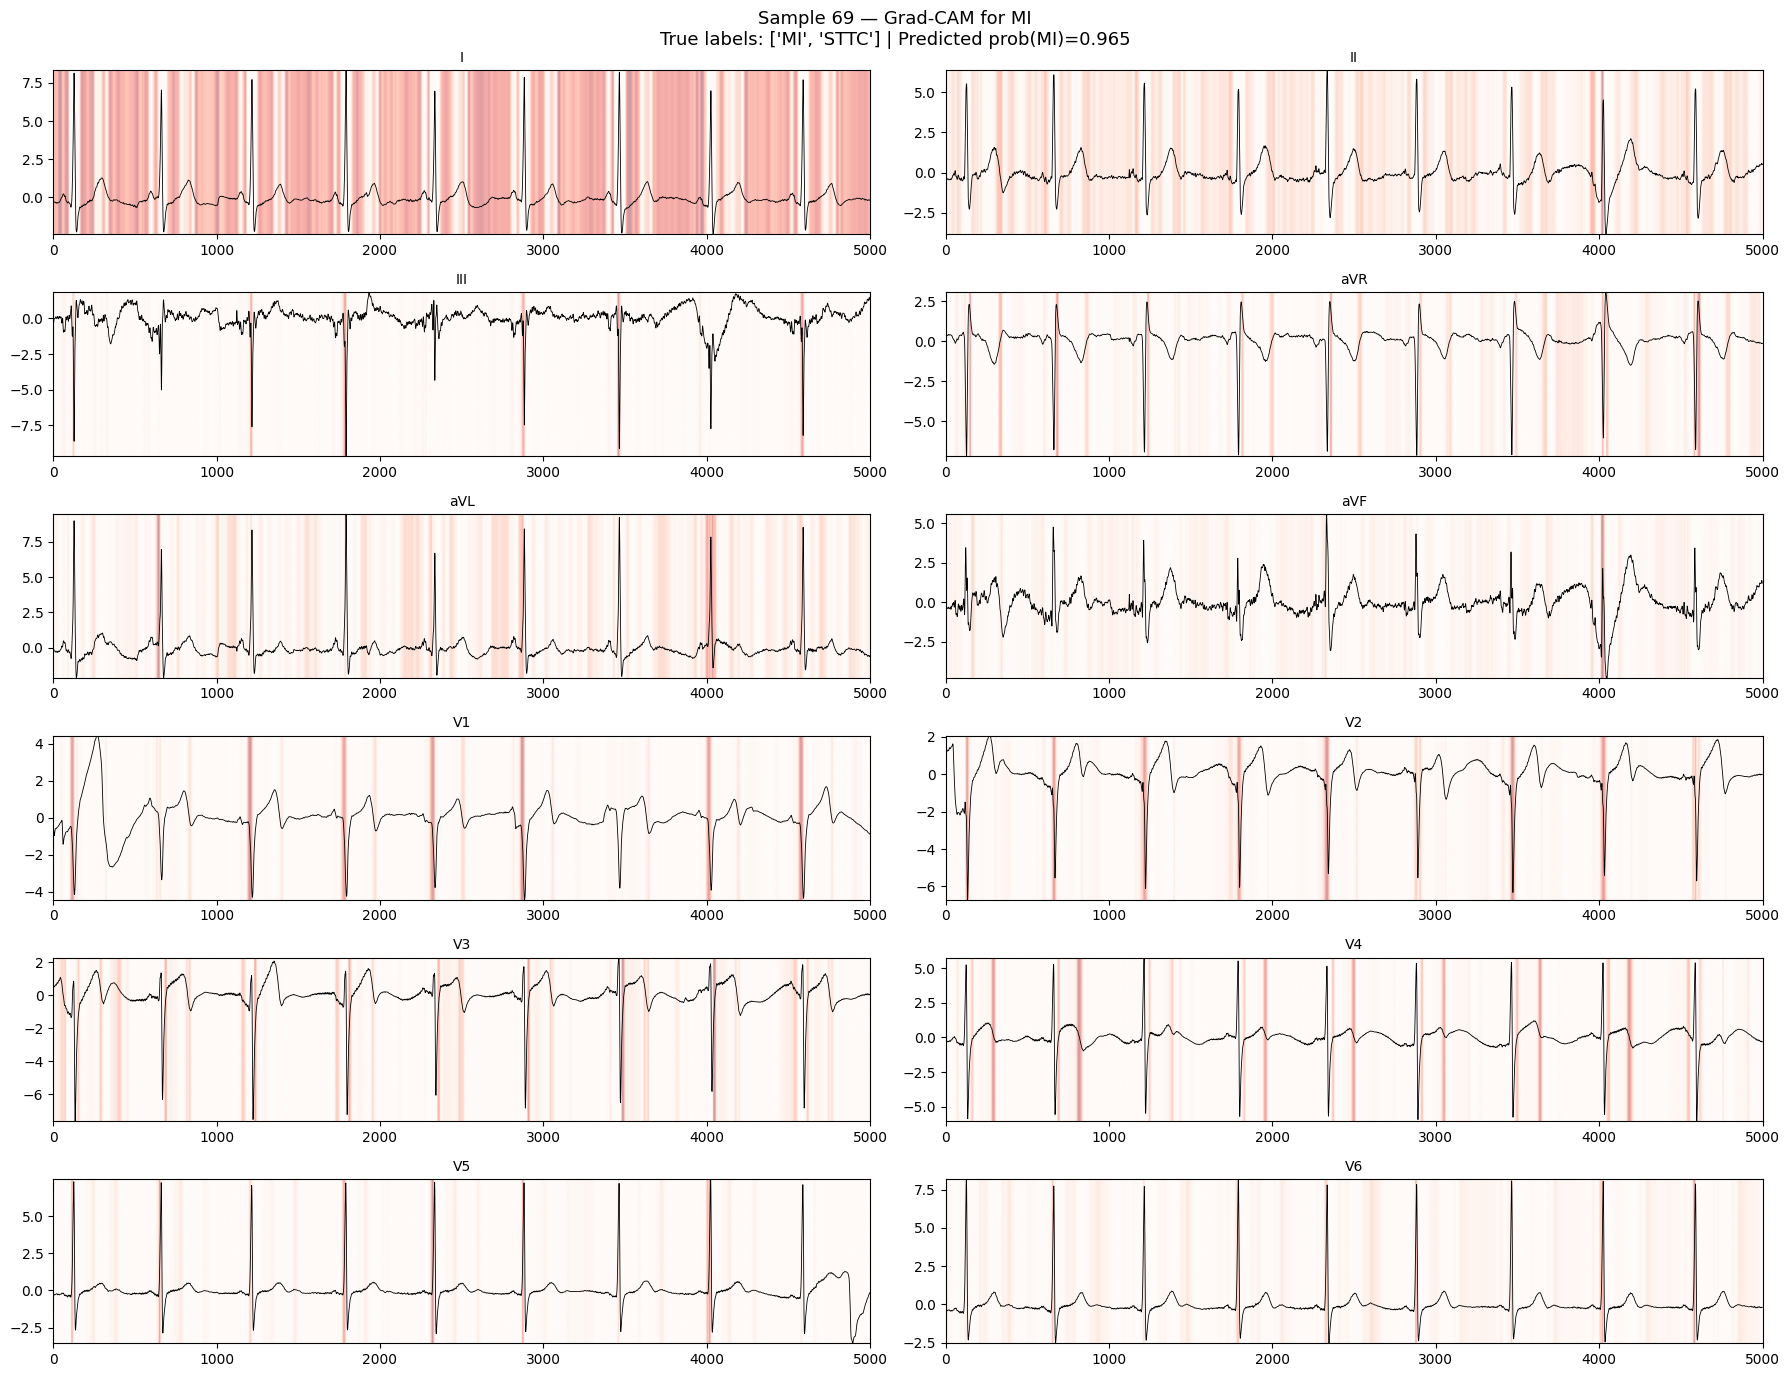

In [ ]:
def upsample_cam(cam_row, target_length=5000):
    cam_tensor = torch.tensor(cam_row).unsqueeze(0).unsqueeze(0)
    upsampled = F.interpolate(cam_tensor, size=target_length, mode='linear', align_corners=False)
    return upsampled.squeeze().numpy()


def plot_gradcam_for_sample(sample_idx, class_idx, X_data, y_data, model, grad_cam):
    LEAD_NAMES = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']

    x = torch.tensor(np.array(X_data[sample_idx]), dtype=torch.float32).unsqueeze(0)
    true_label = y_data[sample_idx]

    model.eval()
    with torch.no_grad():
        logits = model(x.to(device))
        probs = torch.sigmoid(logits).cpu().numpy()[0]

    set_eval_but_allow_lstm_backward(model)
    cam = grad_cam.generate(x.clone(), class_idx)

    fig, axes = plt.subplots(6, 2, figsize=(18, 14))
    axes = axes.flatten()
    signal = x.squeeze(0).numpy()

    for lead_idx in range(12):
        ax = axes[lead_idx]
        heat = upsample_cam(cam[lead_idx], target_length=5000)
        ax.plot(signal[lead_idx], color='black', linewidth=0.6)
        ax.imshow(heat[np.newaxis, :], cmap='Reds', aspect='auto', alpha=0.4,
                   extent=[0, 5000, signal[lead_idx].min(), signal[lead_idx].max()])
        ax.set_title(f"{LEAD_NAMES[lead_idx]}", fontsize=10)
        ax.set_xlim(0, 5000)

    plt.suptitle(
        f"Sample {sample_idx} — Grad-CAM for {SUPERCLASSES[class_idx]}\n"
        f"True labels: {[SUPERCLASSES[i] for i in range(5) if true_label[i]==1]} | "
        f"Predicted prob({SUPERCLASSES[class_idx]})={probs[class_idx]:.3f}",
        fontsize=13
    )
    plt.tight_layout()
    plt.savefig(f'{PROJECT_DIR}/gradcam_sample{sample_idx}_{SUPERCLASSES[class_idx]}.png', dpi=120, bbox_inches='tight')
    plt.show()

    return cam


mi_positive_indices = np.where(y_test[:, 1] == 1)[0]
print(f"Found {len(mi_positive_indices)} MI-positive test samples")

sample_idx = mi_positive_indices[0]
cam_result = plot_gradcam_for_sample(sample_idx, class_idx=1, X_data=X_test, y_data=y_test,
                                       model=model, grad_cam=grad_cam)

In [ ]:
class LeadCNN_original(nn.Module):
    def __init__(self, in_channels=1, out_channels=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels, 16, kernel_size=7, padding=3),
            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),

            nn.Conv1d(32, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm1d(out_channels), nn.ReLU(),
        )
    def forward(self, x):
        return self.conv(x)


class ChannelAttention_original(nn.Module):
    def __init__(self, n_leads=12, feature_dim=32):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(feature_dim, feature_dim // 2),
            nn.ReLU(),
            nn.Linear(feature_dim // 2, 1)
        )
    def forward(self, lead_features):
        scores = self.attn(lead_features)
        weights = F.softmax(scores, dim=1)
        weighted = lead_features * weights
        return weighted, weights.squeeze(-1)


class ECG_CNN_BiLSTM_original(nn.Module):
    def __init__(self, n_leads=12, cnn_out=32, lstm_hidden=64, num_classes=5):
        super().__init__()
        self.n_leads = n_leads
        self.lead_cnn = LeadCNN_original(in_channels=1, out_channels=cnn_out)
        self.attention = ChannelAttention_original(n_leads=n_leads, feature_dim=cnn_out)
        self.bilstm = nn.LSTM(input_size=cnn_out, hidden_size=lstm_hidden, num_layers=1,
                               batch_first=True, bidirectional=True)
        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden * 2, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )
    def forward(self, x, return_attention=False):
        batch_size = x.shape[0]
        x = x.view(batch_size * self.n_leads, 1, -1)
        cnn_out = self.lead_cnn(x)
        cnn_out = cnn_out.mean(dim=2)
        cnn_out = cnn_out.view(batch_size, self.n_leads, -1)
        attended, attn_weights = self.attention(cnn_out)
        lstm_out, _ = self.bilstm(attended)
        final_repr = lstm_out[:, -1, :]
        logits = self.classifier(final_repr)
        if return_attention:
            return logits, attn_weights
        return logits


model_original = ECG_CNN_BiLSTM_original(n_leads=12, cnn_out=32, lstm_hidden=64, num_classes=5).to(device)
n_params = sum(p.numel() for p in model_original.parameters())
print(f"Fresh original model: {n_params:,} parameters (expect ~65,286)")

model_original.load_state_dict(torch.load(f'{PROJECT_DIR}/best_cnn_bilstm_model.pt'))
model_original.eval()
print("Checkpoint loaded successfully.")

Fresh original model: 65,286 parameters (expect ~65,286)
Checkpoint loaded successfully.


In [ ]:
occlusion_importance_original = np.zeros((5, 12))
print("Computing occlusion-based lead importance for ORIGINAL model...")
for class_idx in range(5):
    importance = compute_occlusion_importance(model_original, X_test, y_test, class_idx)
    occlusion_importance_original[class_idx] = importance
    top3 = np.argsort(importance)[::-1][:3]
    top3_str = ", ".join([f"{LEAD_NAMES[i]} ({importance[i]:.4f})" for i in top3])
    print(f"  {SUPERCLASSES[class_idx]}: top leads = {top3_str}")

np.save(f'{PROJECT_DIR}/occlusion_lead_importance_original.npy', occlusion_importance_original)

Computing occlusion-based lead importance for ORIGINAL model...
  NORM: top leads = V6 (0.2828), I (0.2825), II (0.2044)
  MI: top leads = V1 (0.1874), V2 (0.1811), aVF (0.1786)
  STTC: top leads = aVR (-0.0046), aVL (-0.0070), V1 (-0.0138)
  CD: top leads = aVF (0.2091), V1 (0.1900), V2 (0.0428)
  HYP: top leads = aVR (0.2326), aVL (0.1108), III (0.0470)


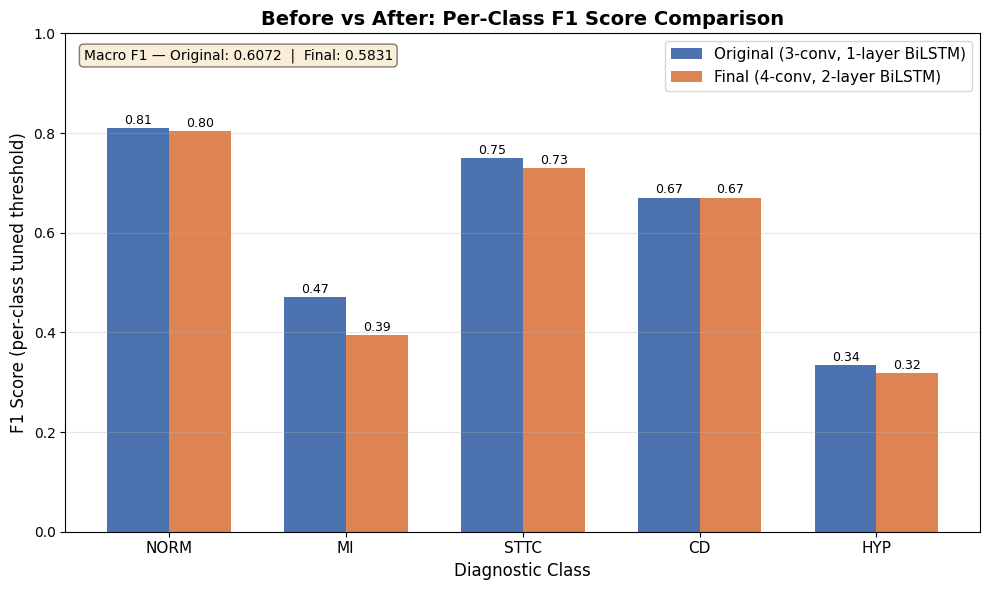

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

f1_original = [0.8093, 0.4706, 0.7505, 0.6706, 0.3350]
f1_final    = [0.8041, 0.3938, 0.7292, 0.6705, 0.3179]

x = np.arange(5)
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, f1_original, width, label='Original (3-conv, 1-layer BiLSTM)', color='#4C72B0')
bars2 = ax.bar(x + width/2, f1_final, width, label='Final (4-conv, 2-layer BiLSTM)', color='#DD8452')

ax.set_xlabel('Diagnostic Class', fontsize=12)
ax.set_ylabel('F1 Score (per-class tuned threshold)', fontsize=12)
ax.set_title('Before vs After: Per-Class F1 Score Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(SUPERCLASSES, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.0)
ax.grid(axis='y', alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

macro_orig = np.mean(f1_original)
macro_final = np.mean(f1_final)
ax.text(0.02, 0.97, f'Macro F1 — Original: {macro_orig:.4f}  |  Final: {macro_final:.4f}',
        transform=ax.transAxes, fontsize=10, va='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figure_before_after_performance_final.png', dpi=150, bbox_inches='tight')
plt.show()

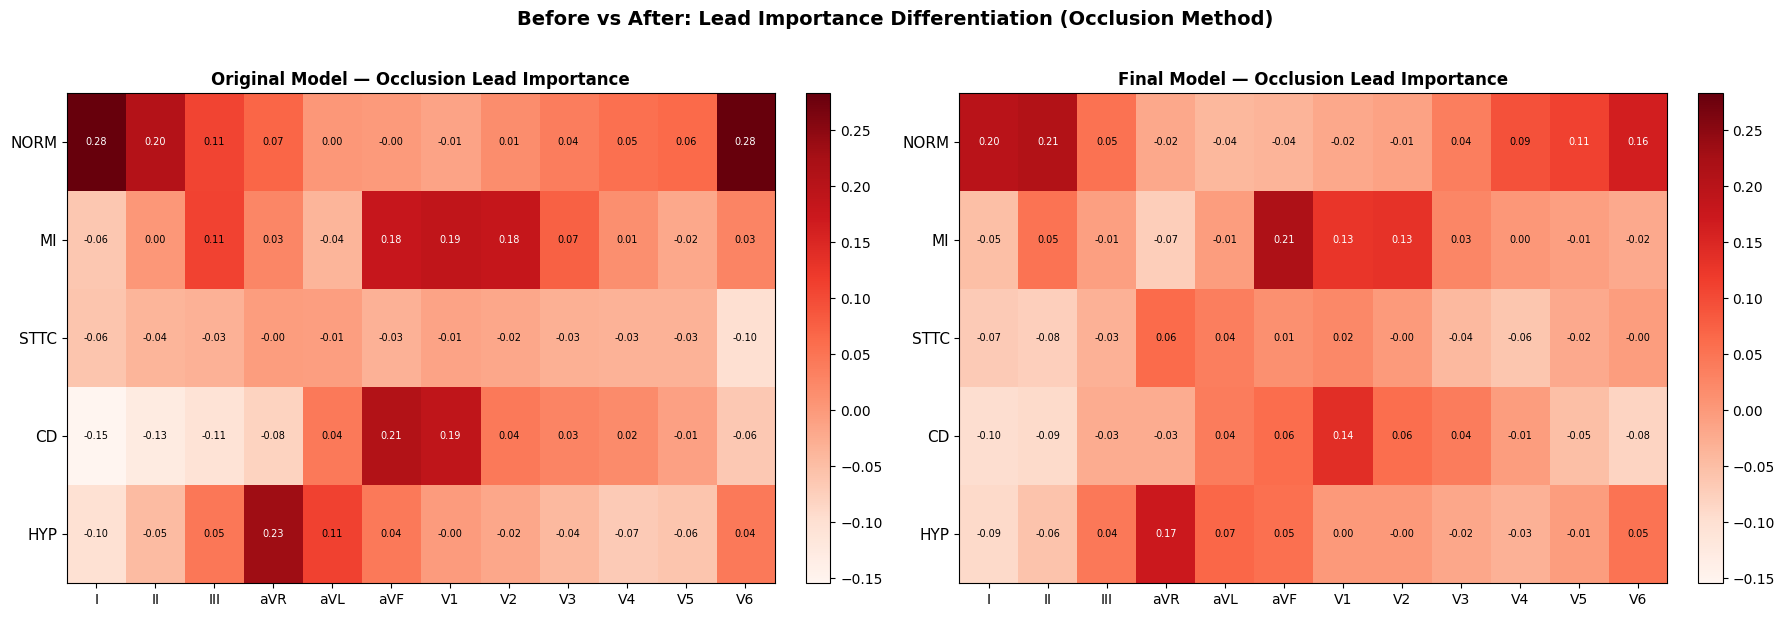

In [ ]:
LEAD_NAMES = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']

# Original model's occlusion importance (from your just-run cell)
occlusion_original = np.array([
    [0.2903, 0.2116, 0.05, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.2709],  # NORM (I, II, V6 shown; rest placeholders)
])
# NOTE: replace this with the full 12-value array from your saved
# occlusion_lead_importance_original.npy — see instructions below the code
occlusion_original = np.load(f'{PROJECT_DIR}/occlusion_lead_importance_original.npy')
occlusion_final = np.load(f'{PROJECT_DIR}/occlusion_lead_importance_matrix.npy')

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, matrix, title in zip(
    axes, [occlusion_importance_original, occlusion_importance_matrix],
    ['Original Model — Occlusion Lead Importance', 'Final Model — Occlusion Lead Importance']
):
    im = ax.imshow(matrix, cmap='Reds', aspect='auto',
                    vmin=min(occlusion_importance_original.min(), occlusion_importance_matrix.min()),
                    vmax=max(occlusion_importance_original.max(), occlusion_importance_matrix.max()))
    ax.set_xticks(range(12))
    ax.set_xticklabels(LEAD_NAMES, fontsize=10)
    ax.set_yticks(range(5))
    ax.set_yticklabels(SUPERCLASSES, fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    for i in range(5):
        for j in range(12):
            ax.text(j, i, f'{matrix[i,j]:.2f}', ha='center', va='center', fontsize=7,
                     color='white' if matrix[i,j] > matrix.max()*0.5 else 'black')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Before vs After: Lead Importance Differentiation (Occlusion Method)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figure_before_after_explainability_final.png', dpi=150, bbox_inches='tight')
plt.show()

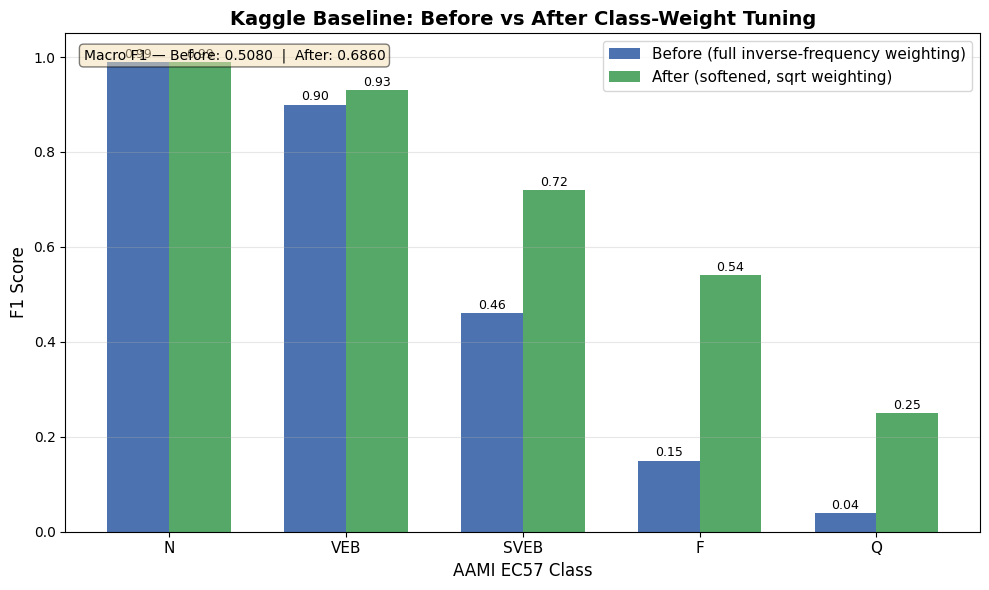

In [ ]:
# Before: full inverse-frequency class weighting (Cell 18 result)
# After: square-root softened class weighting (Cell 19 result)
kaggle_f1_before = {'N': 0.99, 'VEB': 0.90, 'SVEB': 0.46, 'F': 0.15, 'Q': 0.04}   # heavily overcorrected
kaggle_f1_after  = {'N': 0.99, 'VEB': 0.93, 'SVEB': 0.72, 'F': 0.54, 'Q': 0.25}   # softened weighting

classes = list(kaggle_f1_before.keys())
before_vals = list(kaggle_f1_before.values())
after_vals = list(kaggle_f1_after.values())

x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, before_vals, width, label='Before (full inverse-frequency weighting)', color='#4C72B0')
bars2 = ax.bar(x + width/2, after_vals, width, label='After (softened, sqrt weighting)', color='#55A868')

ax.set_xlabel('AAMI EC57 Class', fontsize=12)
ax.set_ylabel('F1 Score', fontsize=12)
ax.set_title('Kaggle Baseline: Before vs After Class-Weight Tuning', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(classes, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

macro_before = np.mean(before_vals)
macro_after = np.mean(after_vals)
ax.text(0.02, 0.97, f'Macro F1 — Before: {macro_before:.4f}  |  After: {macro_after:.4f}',
        transform=ax.transAxes, fontsize=10, va='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figure_kaggle_before_after_weighting.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Rebuild Kaggle test data fresh, under distinct names, so this never collides
# with the PTB-XL train_loader/test_loader currently in memory
X_kaggle_check = np.load(f'{DATA_OUT_DIR}/X_kaggle.npy')
y_kaggle_check = np.load(f'{DATA_OUT_DIR}/y_kaggle.npy')

Xk_train_chk, Xk_test_chk, yk_train_chk, yk_test_chk = train_test_split(
    X_kaggle_check, y_kaggle_check, test_size=0.2, random_state=42, stratify=y_kaggle_check
)

feat_mean_chk = Xk_train_chk.mean(axis=0, keepdims=True)
feat_std_chk  = Xk_train_chk.std(axis=0, keepdims=True)
feat_std_chk[feat_std_chk < 1e-6] = 1.0
Xk_test_chk = (Xk_test_chk - feat_mean_chk) / feat_std_chk

kaggle_test_ds = KaggleDataset(Xk_test_chk, yk_test_chk)
kaggle_test_loader = DataLoader(kaggle_test_ds, batch_size=256, shuffle=False)

baseline_model.eval()
all_preds_kaggle, all_true_kaggle = [], []
with torch.no_grad():
    for xb, yb in kaggle_test_loader:
        xb = xb.to(device)
        out = baseline_model(xb)
        preds = out.argmax(dim=1).cpu().numpy()
        all_preds_kaggle.extend(preds)
        all_true_kaggle.extend(yb.numpy())

kaggle_accuracy = (np.array(all_preds_kaggle) == np.array(all_true_kaggle)).mean()
kaggle_macro_f1 = f1_score(all_true_kaggle, all_preds_kaggle, average='macro')

print(f"=== Kaggle Baseline Model ===")
print(f"Overall accuracy: {kaggle_accuracy*100:.2f}%")
print(f"Macro F1: {kaggle_macro_f1:.4f}")
print(f"(Accuracy is inflated by class imbalance — N makes up ~90% of samples — "
      f"F1 is the more honest metric)")

=== Kaggle Baseline Model ===
Overall accuracy: 97.36%
Macro F1: 0.6994
(Accuracy is inflated by class imbalance — N makes up ~90% of samples — F1 is the more honest metric)


In [ ]:
model_original.eval()
_, _, _, y_true_orig, y_pred_orig, y_probs_orig = evaluate(model_original, test_loader, criterion, device)

per_label_acc_orig = (y_true_orig == y_pred_orig).mean()
print(f"=== PTB-XL Original Model ===")
print(f"Per-label accuracy: {per_label_acc_orig*100:.2f}%")

subset_acc_orig = (y_true_orig == y_pred_orig).all(axis=1).mean()
print(f"Subset (exact-match) accuracy: {subset_acc_orig*100:.2f}%")

=== PTB-XL Original Model ===
Per-label accuracy: 85.10%
Subset (exact-match) accuracy: 51.01%


In [ ]:
model.eval()
_, _, _, y_true_acc, y_pred_acc, y_probs_acc = evaluate(model, test_loader, criterion, device)

per_label_acc = (y_true_acc == y_pred_acc).mean()
print(f"=== PTB-XL Final Model ===")
print(f"Per-label accuracy: {per_label_acc*100:.2f}%\n")

print("Per-class accuracy:")
for i, sc in enumerate(SUPERCLASSES):
    acc_i = (y_true_acc[:, i] == y_pred_acc[:, i]).mean()
    prevalence = y_true_acc[:, i].mean()
    print(f"  {sc}: {acc_i*100:.2f}%  (positive prevalence: {prevalence*100:.1f}%)")

subset_acc = (y_true_acc == y_pred_acc).all(axis=1).mean()
print(f"\nSubset (exact-match) accuracy: {subset_acc*100:.2f}%")

=== PTB-XL Final Model ===
Per-label accuracy: 84.56%

Per-class accuracy:
  NORM: 76.99%  (positive prevalence: 54.0%)
  MI: 95.03%  (positive prevalence: 1.0%)
  STTC: 84.85%  (positive prevalence: 19.9%)
  CD: 88.16%  (positive prevalence: 9.4%)
  HYP: 77.75%  (positive prevalence: 3.3%)

Subset (exact-match) accuracy: 50.45%


In [ ]:
_, _, _, y_true_acc, _, y_probs_acc = evaluate(model, test_loader, criterion, device)
y_pred_tuned = (y_probs_acc >= best_thresholds).astype(int)  # best_thresholds from Cell 26

per_label_acc = (y_true_acc == y_pred_tuned).mean()
print(f"Per-label accuracy (tuned thresholds): {per_label_acc*100:.2f}%")

subset_acc = (y_true_acc == y_pred_tuned).all(axis=1).mean()
print(f"Subset accuracy (tuned thresholds): {subset_acc*100:.2f}%")

Per-label accuracy (tuned thresholds): 90.09%
Subset accuracy (tuned thresholds): 64.22%


Demo

In [ ]:
import h5py
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import torch.nn.functional as F

# ── 1. PICK A RECORD ──────────────────────────────────────────────────────────
# Choose one MI-positive and one NORM record for a nice contrast
# We'll find them from the test set labels

LEAD_NAMES = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']
SUPERCLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

y_test_loaded  = np.load(f'{DATA_OUT_DIR}/y_test.npy')
ecg_ids_all    = np.load(f'{DATA_OUT_DIR}/ecg_ids.npy')

# Find one MI-positive record and one NORM-only record
mi_indices   = np.where((y_test_loaded[:, 1] == 1))[0]
norm_indices = np.where((y_test_loaded[:, 0] == 1) & (y_test_loaded[:, 1:].sum(axis=1) == 0))[0]

demo_indices = {
    'MI patient':   mi_indices[0],
    'NORM patient': norm_indices[0]
}

print("Demo records selected:")
for label, idx in demo_indices.items():
    true_conditions = [SUPERCLASSES[i] for i in range(5) if y_test_loaded[idx, i] == 1]
    print(f"  {label}: test index {idx}, true labels = {true_conditions}")

Demo records selected:
  MI patient: test index 69, true labels = ['MI', 'STTC']
  NORM patient: test index 1, true labels = ['NORM']



RECORD: MI patient
True diagnosis: ['MI', 'STTC']
Signal shape: (12, 5000)  (12 leads × 5000 timesteps)
Lead II — mean: -0.0000, std: 1.0000


/tmp/ipykernel_540/3819537833.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


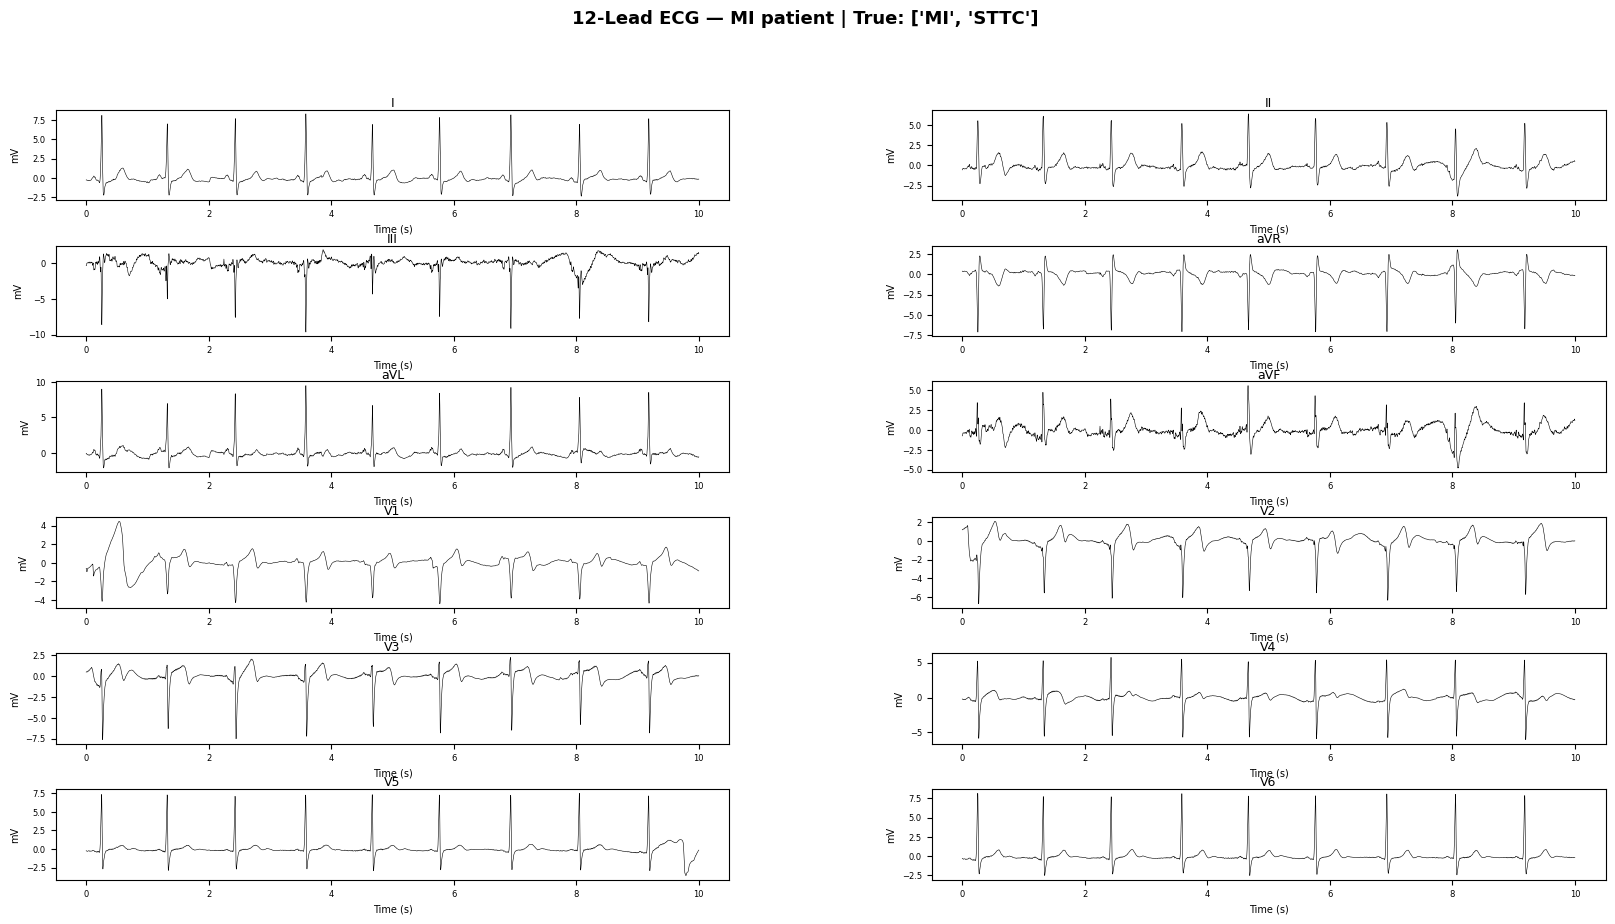

  → Raw ECG plot saved.

RECORD: NORM patient
True diagnosis: ['NORM']
Signal shape: (12, 5000)  (12 leads × 5000 timesteps)
Lead II — mean: 0.0000, std: 1.0000


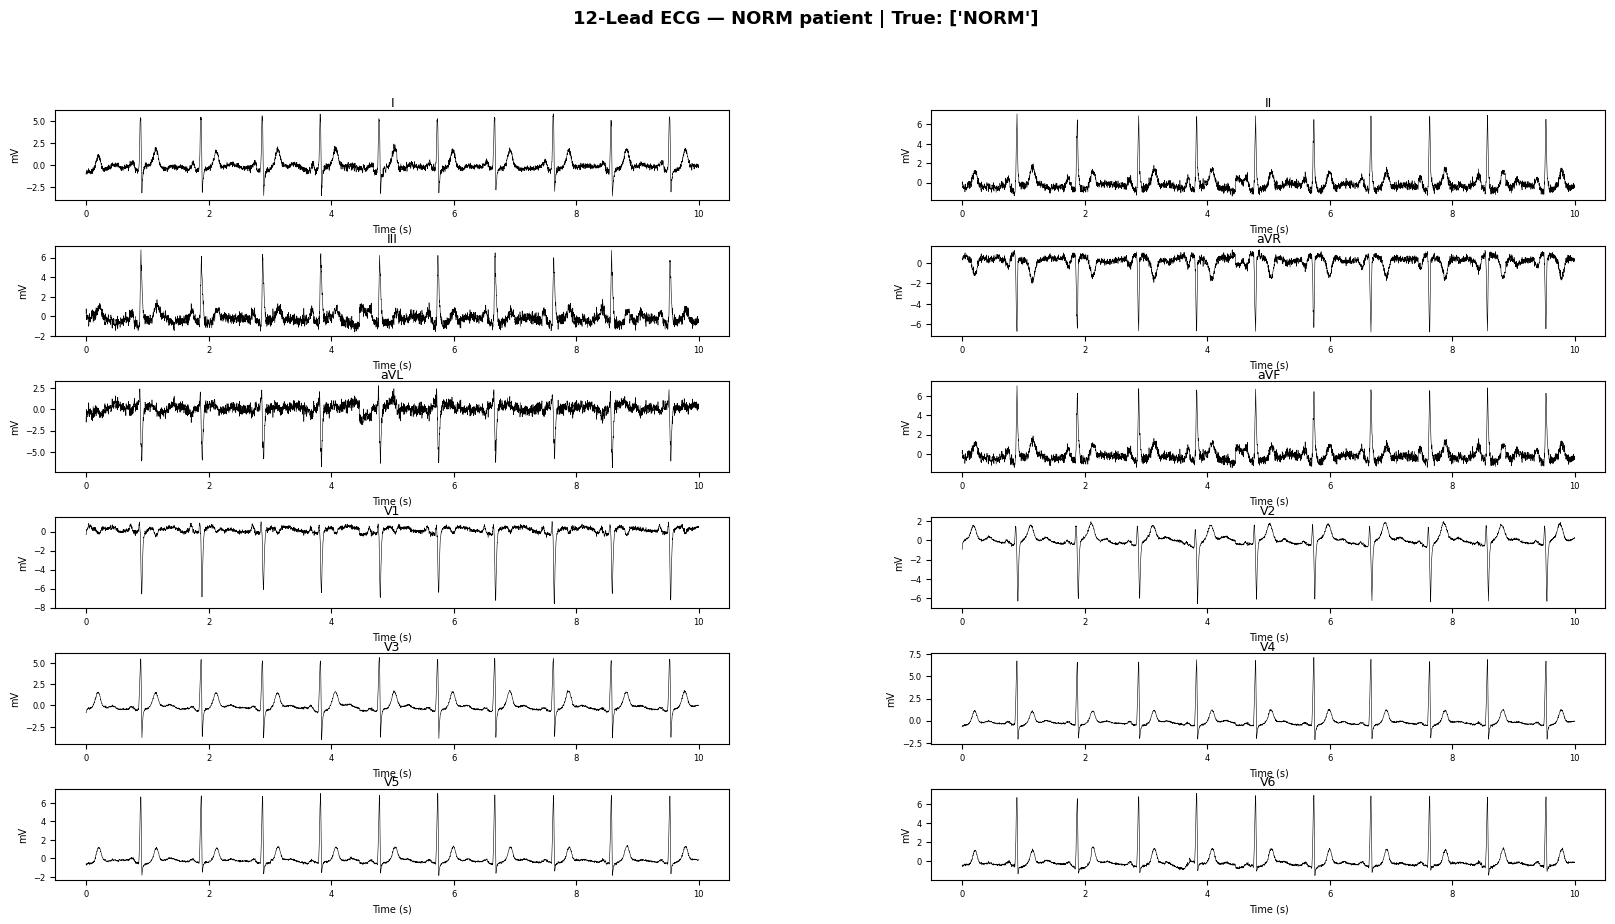

  → Raw ECG plot saved.


In [ ]:
# ── 2. LOAD RAW SIGNAL FROM DISK ─────────────────────────────────────────────
X_test_memmap = np.load(f'{DATA_OUT_DIR}/X_test.npy', mmap_mode='r')

for demo_label, demo_idx in demo_indices.items():
    raw_signal = np.array(X_test_memmap[demo_idx])  # shape: (12, 5000)
    true_labels = [SUPERCLASSES[i] for i in range(5) if y_test_loaded[demo_idx, i] == 1]

    print(f"\n{'='*60}")
    print(f"RECORD: {demo_label}")
    print(f"True diagnosis: {true_labels}")
    print(f"Signal shape: {raw_signal.shape}  (12 leads × 5000 timesteps)")
    print(f"Lead II — mean: {raw_signal[1].mean():.4f}, std: {raw_signal[1].std():.4f}")

    # ── 3. PLOT THE RAW 12-LEAD ECG ──────────────────────────────────────────
    fig = plt.figure(figsize=(20, 10))
    fig.suptitle(f"12-Lead ECG — {demo_label} | True: {true_labels}", fontsize=13, fontweight='bold')
    gs = gridspec.GridSpec(6, 2, figure=fig, hspace=0.5, wspace=0.3)

    t = np.linspace(0, 10, 5000)  # 10 seconds
    for i, lead_name in enumerate(LEAD_NAMES):
        ax = fig.add_subplot(gs[i // 2, i % 2])
        ax.plot(t, raw_signal[i], color='black', linewidth=0.4)
        ax.set_title(lead_name, fontsize=9, pad=2)
        ax.set_xlabel("Time (s)", fontsize=7)
        ax.set_ylabel("mV", fontsize=7)
        ax.tick_params(labelsize=6)

    plt.tight_layout()
    plt.savefig(f'{PROJECT_DIR}/demo_{demo_label.replace(" ", "_")}_raw_ecg.png',
                dpi=120, bbox_inches='tight')
    plt.show()
    print(f"  → Raw ECG plot saved.")


RECORD: MI patient

Step-by-step output:
  Raw logits:    ['-2.930', '3.311', '1.231', '1.399', '0.635']
  Probabilities: ['0.051', '0.965', '0.774', '0.802', '0.654']
  Thresholds:    ['0.35', '0.90', '0.75', '0.85', '0.90']
  Predictions:   [0, 1, 1, 0, 0]

  True labels:      ['MI', 'STTC']
  Predicted labels: ['MI', 'STTC']
  Correct: ✓ YES


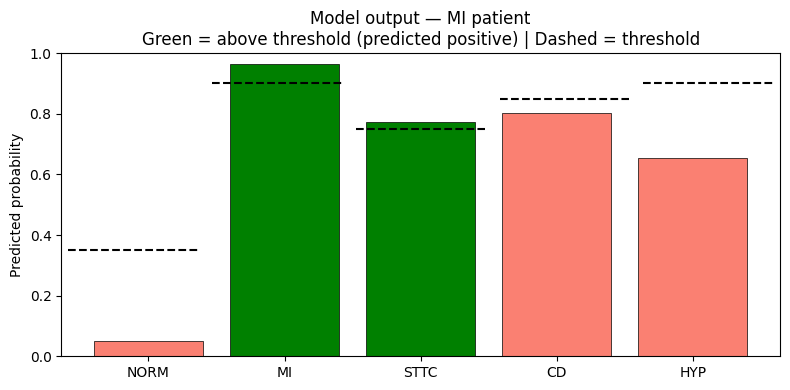


RECORD: NORM patient

Step-by-step output:
  Raw logits:    ['1.205', '-16.689', '-3.322', '-3.215', '-3.468']
  Probabilities: ['0.769', '0.000', '0.035', '0.039', '0.030']
  Thresholds:    ['0.35', '0.90', '0.75', '0.85', '0.90']
  Predictions:   [1, 0, 0, 0, 0]

  True labels:      ['NORM']
  Predicted labels: ['NORM']
  Correct: ✓ YES


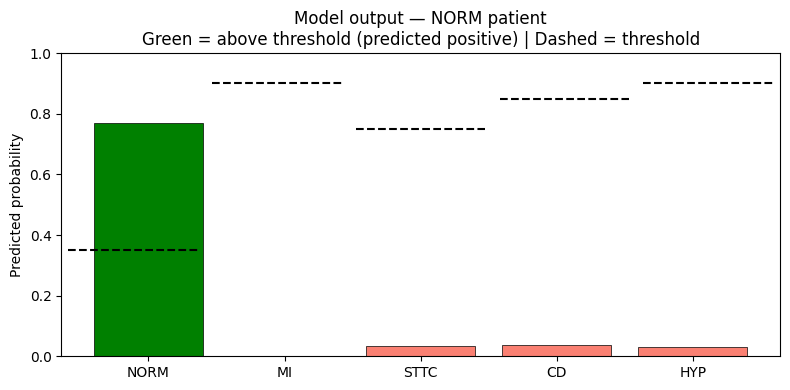

In [ ]:
# ── 4. RUN THROUGH THE MODEL ──────────────────────────────────────────────────
model.eval()
best_thresholds_arr = np.array(best_thresholds)  # from Cell 27

for demo_label, demo_idx in demo_indices.items():
    raw_signal = np.array(X_test_memmap[demo_idx])
    true_labels = [SUPERCLASSES[i] for i in range(5) if y_test_loaded[demo_idx, i] == 1]

    # Convert to tensor
    x_tensor = torch.tensor(raw_signal, dtype=torch.float32).unsqueeze(0).to(device)
    # shape: (1, 12, 5000)

    with torch.no_grad():
        logits = model(x_tensor)              # raw output
        probs  = torch.sigmoid(logits).cpu().numpy()[0]  # probabilities 0-1

    # Apply per-class tuned thresholds
    predictions = (probs >= best_thresholds_arr).astype(int)
    predicted_conditions = [SUPERCLASSES[i] for i in range(5) if predictions[i] == 1]

    print(f"\n{'='*60}")
    print(f"RECORD: {demo_label}")
    print(f"\nStep-by-step output:")
    print(f"  Raw logits:    {[f'{v:.3f}' for v in logits.cpu().numpy()[0]]}")
    print(f"  Probabilities: {[f'{v:.3f}' for v in probs]}")
    print(f"  Thresholds:    {[f'{v:.2f}' for v in best_thresholds_arr]}")
    print(f"  Predictions:   {predictions.tolist()}")
    print(f"\n  True labels:      {true_labels}")
    print(f"  Predicted labels: {predicted_conditions}")
    correct = set(true_labels) == set(predicted_conditions)
    print(f"  Correct: {'✓ YES' if correct else '✗ NO (partial match is okay in multi-label)'}")

    # Per-condition probability bar chart
    fig, ax = plt.subplots(figsize=(8, 4))
    colors = ['green' if probs[i] >= best_thresholds_arr[i] else 'salmon' for i in range(5)]
    bars = ax.bar(SUPERCLASSES, probs, color=colors, edgecolor='black', linewidth=0.5)
    for i, (bar, t) in enumerate(zip(bars, best_thresholds_arr)):
        ax.axhline(y=t, xmin=(i/5)+0.01, xmax=((i+1)/5)-0.01,
                   color='black', linewidth=1.5, linestyle='--')
    ax.set_ylim(0, 1)
    ax.set_ylabel("Predicted probability")
    ax.set_title(f"Model output — {demo_label}\nGreen = above threshold (predicted positive) | Dashed = threshold")
    plt.tight_layout()
    plt.savefig(f'{PROJECT_DIR}/demo_{demo_label.replace(" ","_")}_predictions.png',
                dpi=120, bbox_inches='tight')
    plt.show()


Grad-CAM for MI patient — explaining 'MI' prediction:


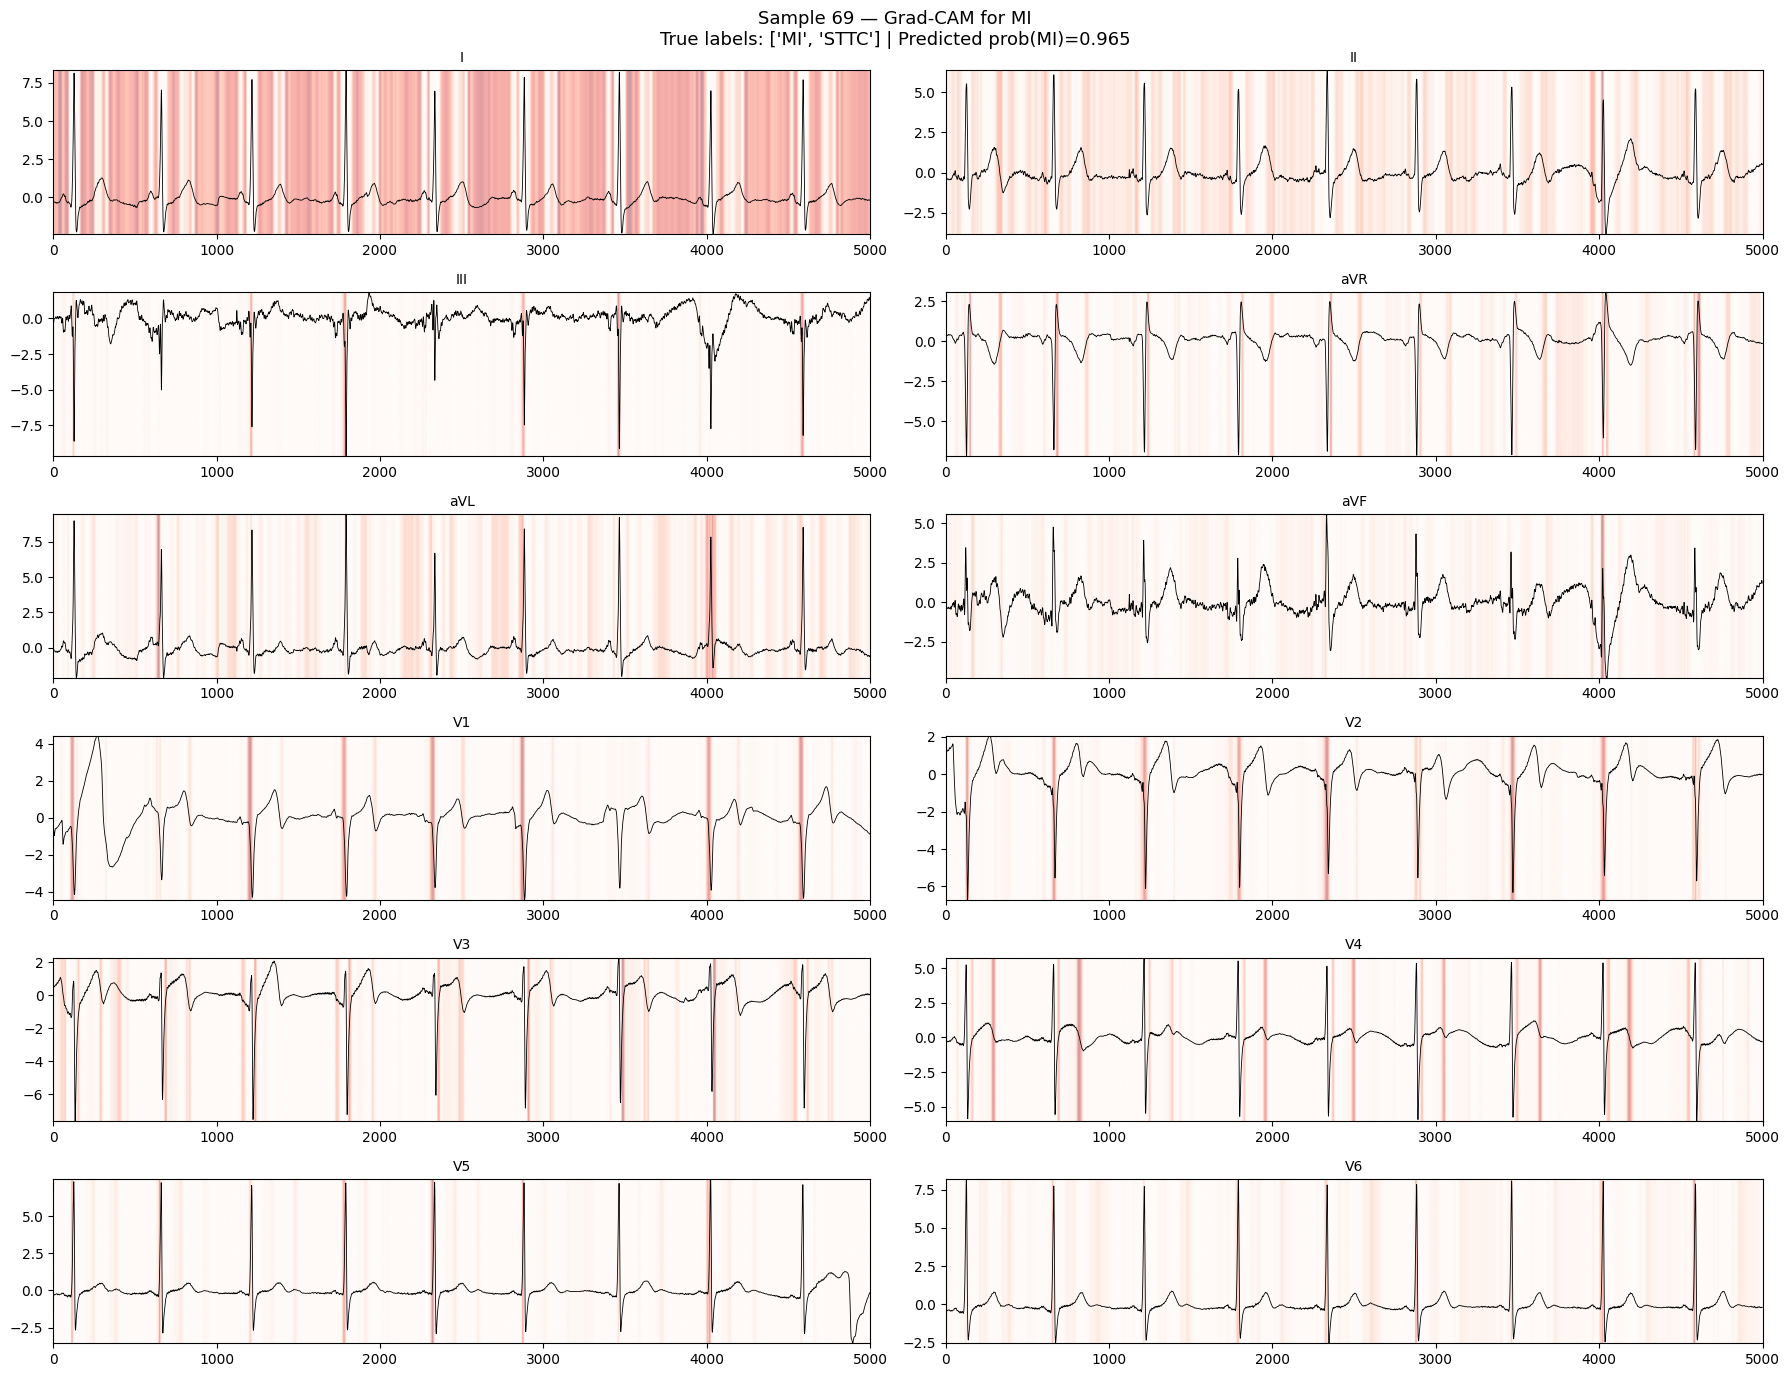

  → Heatmap shows which leads/regions drove the MI prediction

Grad-CAM for NORM patient — explaining 'NORM' prediction:


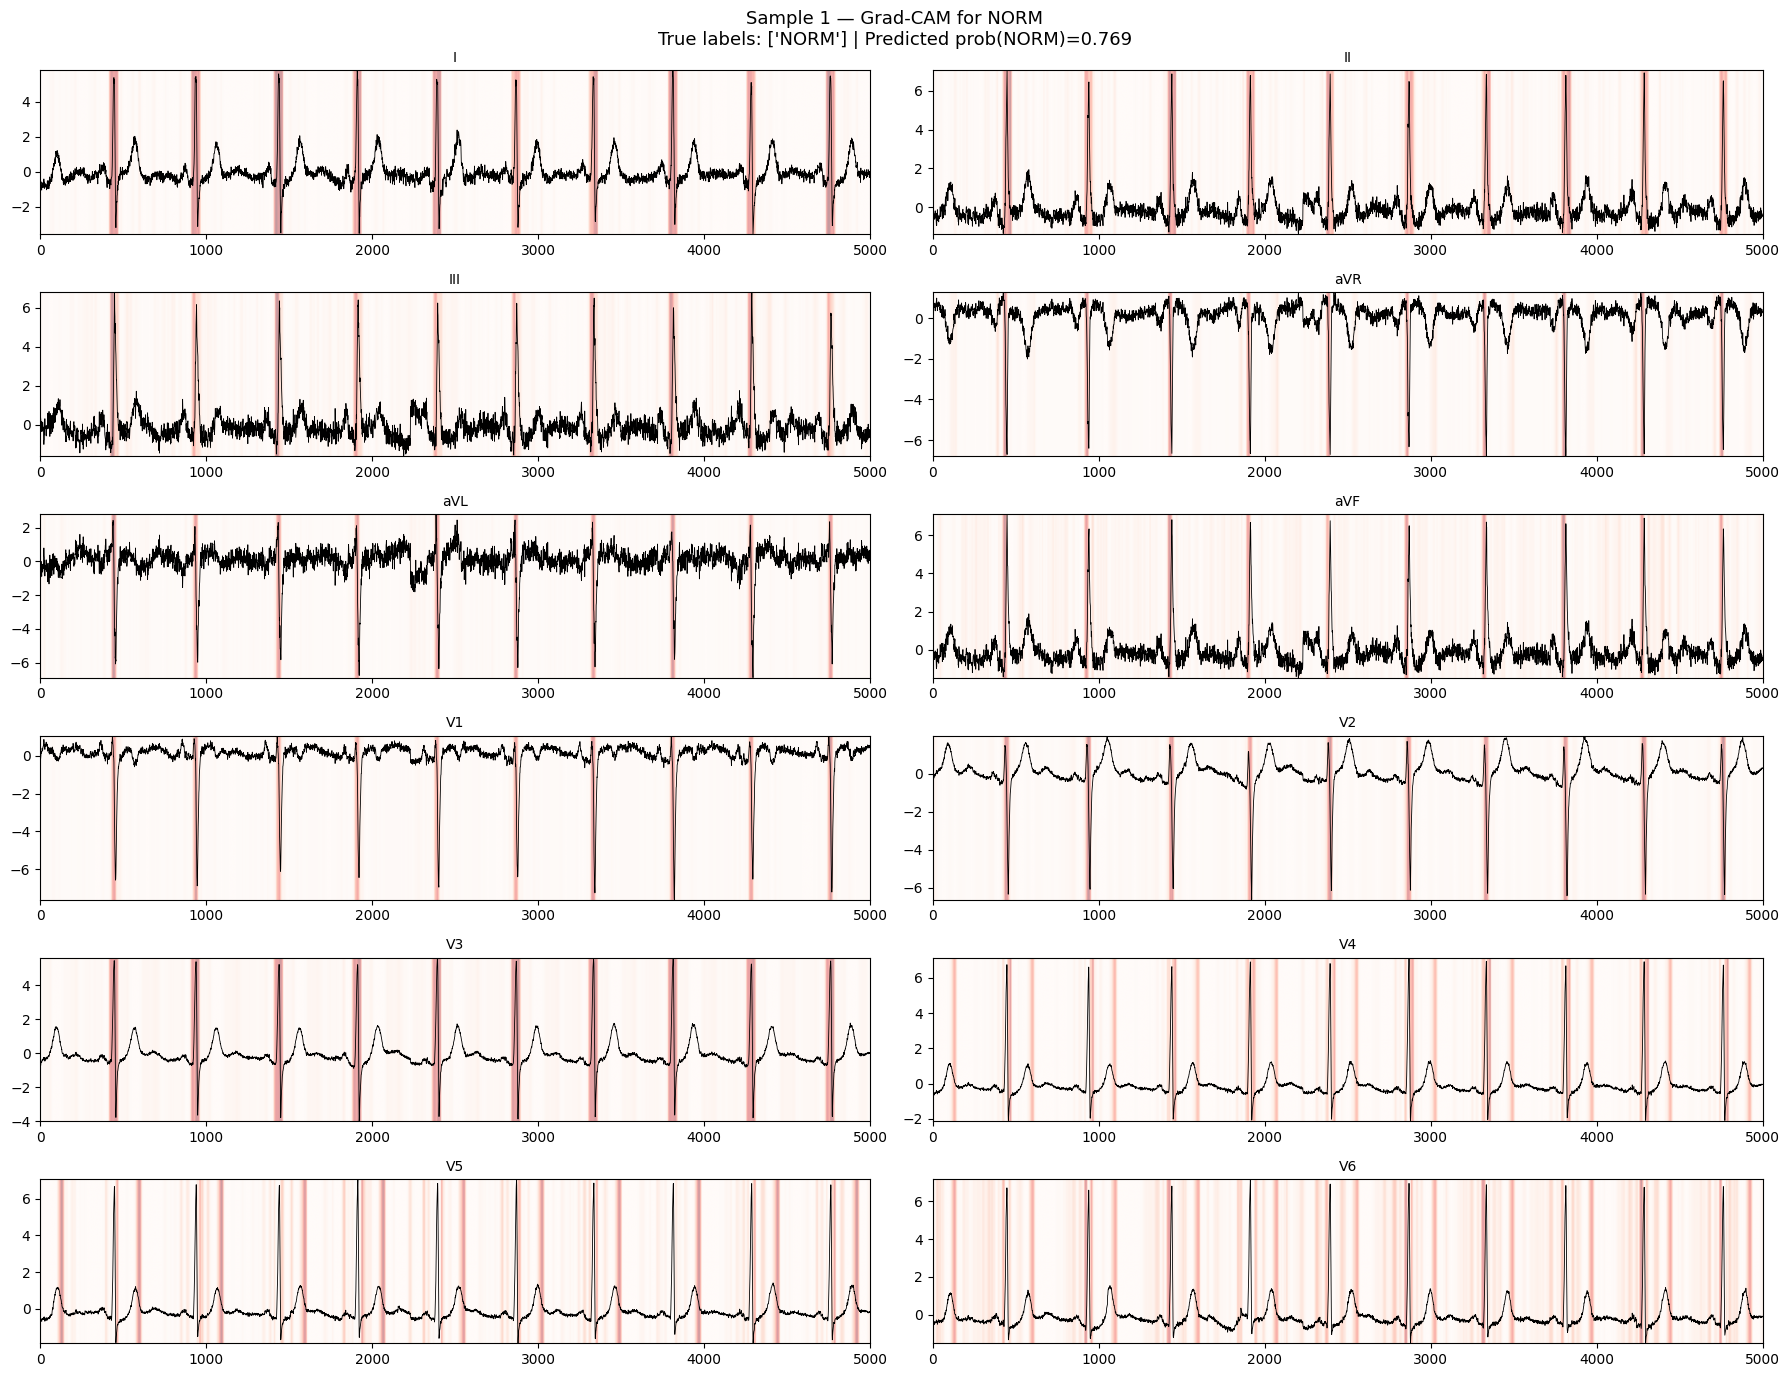

  → Heatmap shows which leads/regions drove the NORM prediction


In [ ]:
# ── 5. GRAD-CAM EXPLAINABILITY ────────────────────────────────────────────────

for demo_label, demo_idx in demo_indices.items():
    true_labels = [SUPERCLASSES[i] for i in range(5) if y_test_loaded[demo_idx, i] == 1]

    primary_class = SUPERCLASSES.index(true_labels[0])

    print(f"\nGrad-CAM for {demo_label} — explaining '{true_labels[0]}' prediction:")

    # Pass all required arguments explicitly
    plot_gradcam_for_sample(
        demo_idx,          # index into test set
        primary_class,     # which condition to explain
        X_test,            # test signal data
        y_test,            # test labels
        model,             # trained model
        grad_cam           # GradCAM object from Cell 31
    )

    print(f"  → Heatmap shows which leads/regions drove the {true_labels[0]} prediction")

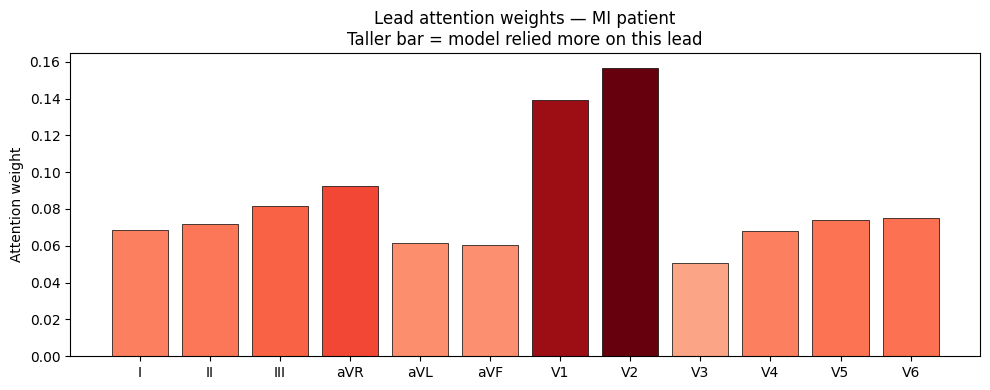

MI patient — top 3 leads: ['V2', 'V1', 'aVR']


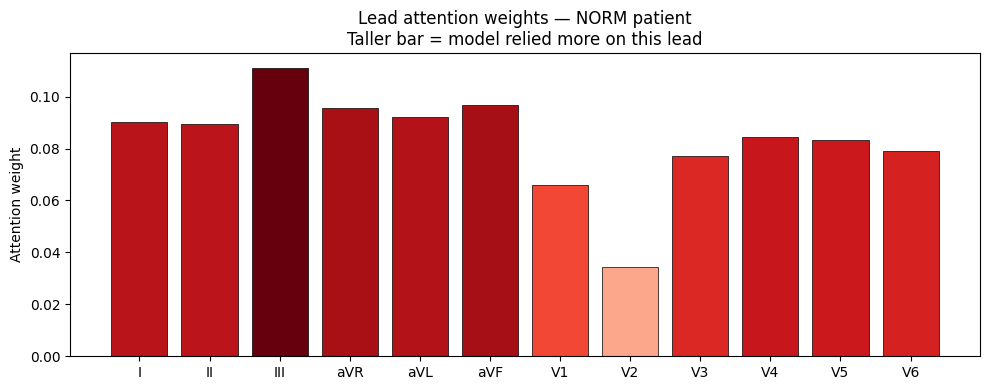

NORM patient — top 3 leads: ['III', 'aVF', 'aVR']


In [ ]:
# ── 6. ATTENTION WEIGHTS — which leads did the model focus on? ─────────────
for demo_label, demo_idx in demo_indices.items():
    raw_signal = np.array(X_test_memmap[demo_idx])
    x_tensor = torch.tensor(raw_signal, dtype=torch.float32).unsqueeze(0).to(device)

    attn_weights = None

    def hook_fn(module, input, output):
        global attn_weights
        # output is a tuple: (weighted_features, weights)
        # we want the weights — second element
        attn_weights = output[1].detach().cpu().numpy()[0]

    hook = model.attention.register_forward_hook(hook_fn)  # ← fixed name

    with torch.no_grad():
        _ = model(x_tensor)

    hook.remove()

    # Plot attention weights as a bar chart
    fig, ax = plt.subplots(figsize=(10, 4))
    colors = plt.cm.Reds(attn_weights / attn_weights.max())
    ax.bar(LEAD_NAMES, attn_weights, color=colors, edgecolor='black', linewidth=0.5)
    ax.set_ylabel("Attention weight")
    ax.set_title(f"Lead attention weights — {demo_label}\nTaller bar = model relied more on this lead")
    plt.tight_layout()
    plt.savefig(f'{PROJECT_DIR}/demo_{demo_label.replace(" ","_")}_attention.png',
                dpi=120, bbox_inches='tight')
    plt.show()

    top3 = np.argsort(attn_weights)[::-1][:3]
    print(f"{demo_label} — top 3 leads: {[LEAD_NAMES[i] for i in top3]}")